# XGBoost: Extreme Gradient Boosting Explained
## Clinical Decision Support: Prioritizing Biopsy Review

Welcome to this comprehensive tutorial on XGBoost (eXtreme Gradient Boosting), one of the most powerful and widely-used machine learning algorithms in data science competitions and real-world applications.

In this tutorial, we'll apply XGBoost to a classic clinical problem: **separating malignant from benign breast masses using measurements taken from a fine-needle aspirate slide**. This demonstrates how machine learning can support diagnostic workflows where the cost of a missed case is high.

> **What this model is, and is not.** The model here is *diagnostic support*: it ranks
> which slides a pathologist should look at first, so that the most concerning cases are
> reviewed soonest. It does not diagnose anyone, and no clinical decision in this notebook
> is made without a clinician. See the note at the end of Section 3 on what a real
> diagnostic model would additionally require.

## What You'll Learn
- **What is XGBoost** and why it's so effective
- **Mathematical foundations** of gradient boosting
- **Hands-on implementation** with a real, published clinical dataset
- **Key parameters** and how to tune them
- **Advanced features** like early stopping and cross-validation
- **Model interpretation** with SHAP values (understanding WHY a case is flagged as concerning)
- **Practical comparisons** with other algorithms
- **Real-world best practices**

---


## 1. Introduction & Setup

First, let's import all necessary libraries and check versions to ensure everything is working correctly.

In [1]:
# Core libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_auc_score, roc_curve
from sklearn.datasets import make_classification
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier

# XGBoost
import xgboost as xgb

# Model interpretation
import shap

# Interactive widgets
from ipywidgets import interact, FloatSlider, IntSlider

# Visualization settings
plt.style.use('default')
sns.set_palette("husl")
plt.rcParams['figure.figsize'] = (10, 6)

# Version checks
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print(f"XGBoost version: {xgb.__version__}")
print(f"SHAP version: {shap.__version__}")

NumPy version: 2.5.3
Pandas version: 3.0.6
XGBoost version: 3.4.1
SHAP version: 0.52.0


### What is XGBoost?

**XGBoost (eXtreme Gradient Boosting)** is an optimized distributed gradient boosting library designed to be highly **efficient**, **flexible**, and **portable**.

#### Key Advantages:
1. **Performance**: Often achieves state-of-the-art results on structured/tabular data
2. **Speed**: Highly optimized implementation with parallel processing
3. **Regularization**: Built-in L1 and L2 regularization to prevent overfitting
4. **Handling Missing Values**: Automatically learns how to handle missing data
5. **Cross-platform**: Works on Windows, Linux, macOS
6. **Scalability**: Can handle large datasets efficiently

#### When to Use XGBoost:
- **Structured/tabular data** (like the cell-nucleus measurements used here)
- **Medium to large datasets**
- **When accuracy is paramount** (as in triaging suspected malignancy)
- **Mixed data types** (numerical + categorical)
- **Measurement and laboratory data** (morphometry, vitals, assay panels)

When NOT to use:
- **Very small datasets** (may overfit)
- **Image/text data** (deep learning is better)
- **When interpretability is critical** (try linear models first, though SHAP helps!)

#### Clinical Applications:
In this tutorial, we'll apply XGBoost to a well-studied clinical problem: **distinguishing malignant from benign breast masses using measurements of cell nuclei**. This demonstrates how XGBoost can support clinical review in a setting where a missed malignancy is the expensive error.


---
## 2. Mathematical Foundation

Understanding how XGBoost works under the hood will help you use it more effectively.

### Gradient Boosting Basics

Gradient boosting builds models **sequentially**, where each new model corrects the errors of the previous models.

**The Process:**
1. Start with an initial prediction (usually the mean)
2. Calculate residuals (errors) from current model
3. Train a new model to predict these residuals
4. Add the new model's predictions to our ensemble
5. Repeat until we have enough models or stop improving

Let's visualize this on a series every hospital analyst recognizes: **daily admission
volume**, which rises through the working week and falls at the weekend.


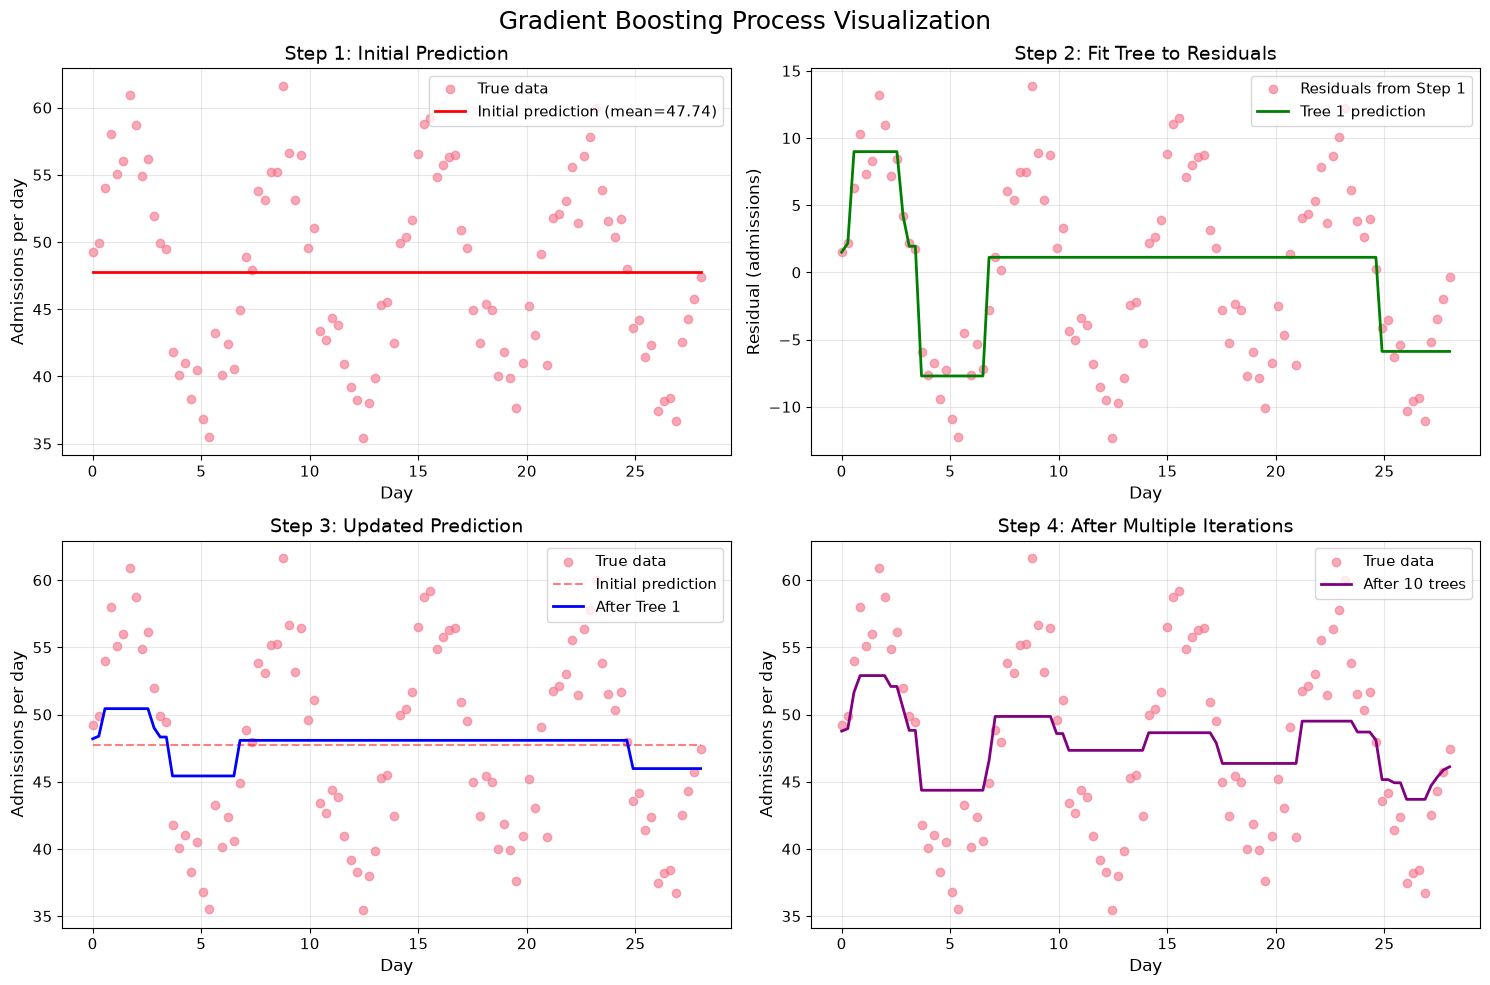

Initial MSE: 47.7910
Final MSE: 26.2279
Improvement: 45.1%


In [2]:
# Create a simple dataset to demonstrate boosting
np.random.seed(42)
X_demo = np.linspace(0, 28, 100).reshape(-1, 1)  # 28 days of data
# Weekly admission cycle: sin with a 7-day period (weekday peaks, weekend troughs)
y_demo = 9 * np.sin(2 * np.pi * X_demo / 7).ravel() + np.random.normal(48, 2.5, X_demo.shape[0])

# Simulate the boosting process
from sklearn.tree import DecisionTreeRegressor

fig, axes = plt.subplots(2, 2, figsize=(15, 10))
fig.suptitle('Gradient Boosting Process Visualization', fontsize=18)

# Initial prediction (mean)
pred_0 = np.full_like(y_demo, y_demo.mean())
residuals_0 = y_demo - pred_0

axes[0,0].scatter(X_demo, y_demo, alpha=0.6, label='True data')
axes[0,0].plot(X_demo, pred_0, 'r-', linewidth=2, label=f'Initial prediction (mean={y_demo.mean():.2f})')
axes[0,0].set_title('Step 1: Initial Prediction', fontsize=14)
axes[0,0].set_xlabel('Day', fontsize=12)
axes[0,0].set_ylabel('Admissions per day', fontsize=12)
axes[0,0].legend(fontsize=11)
axes[0,0].tick_params(axis='both', labelsize=11)
axes[0,0].grid(True, alpha=0.3)

# First tree on residuals
tree_1 = DecisionTreeRegressor(max_depth=3)
tree_1.fit(X_demo, residuals_0)
pred_1 = tree_1.predict(X_demo)

axes[0,1].scatter(X_demo, residuals_0, alpha=0.6, label='Residuals from Step 1')
axes[0,1].plot(X_demo, pred_1, 'g-', linewidth=2, label='Tree 1 prediction')
axes[0,1].set_title('Step 2: Fit Tree to Residuals', fontsize=14)
axes[0,1].set_xlabel('Day', fontsize=12)
axes[0,1].set_ylabel('Residual (admissions)', fontsize=12)
axes[0,1].legend(fontsize=11)
axes[0,1].tick_params(axis='both', labelsize=11)
axes[0,1].grid(True, alpha=0.3)

# Updated prediction
pred_updated_1 = pred_0 + 0.3 * pred_1  # learning rate = 0.3
residuals_1 = y_demo - pred_updated_1

axes[1,0].scatter(X_demo, y_demo, alpha=0.6, label='True data')
axes[1,0].plot(X_demo, pred_0, 'r--', alpha=0.5, label='Initial prediction')
axes[1,0].plot(X_demo, pred_updated_1, 'b-', linewidth=2, label='After Tree 1')
axes[1,0].set_title('Step 3: Updated Prediction', fontsize=14)
axes[1,0].set_xlabel('Day', fontsize=12)
axes[1,0].set_ylabel('Admissions per day', fontsize=12)
axes[1,0].legend(fontsize=11)
axes[1,0].tick_params(axis='both', labelsize=11)
axes[1,0].grid(True, alpha=0.3)

# After multiple iterations
current_pred = pred_0.copy()
for i in range(10):
    residuals = y_demo - current_pred
    tree = DecisionTreeRegressor(max_depth=3)
    tree.fit(X_demo, residuals)
    current_pred += 0.1 * tree.predict(X_demo)

axes[1,1].scatter(X_demo, y_demo, alpha=0.6, label='True data')
axes[1,1].plot(X_demo, current_pred, 'purple', linewidth=2, label='After 10 trees')
axes[1,1].set_title('Step 4: After Multiple Iterations', fontsize=14)
axes[1,1].set_xlabel('Day', fontsize=12)
axes[1,1].set_ylabel('Admissions per day', fontsize=12)
axes[1,1].legend(fontsize=11)
axes[1,1].tick_params(axis='both', labelsize=11)
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f"Initial MSE: {np.mean((y_demo - pred_0)**2):.4f}")
print(f"Final MSE: {np.mean((y_demo - current_pred)**2):.4f}")
print(f"Improvement: {((np.mean((y_demo - pred_0)**2) - np.mean((y_demo - current_pred)**2)) / np.mean((y_demo - pred_0)**2) * 100):.1f}%")


In [3]:
# # Visualizing how the decision tree chooses split points
# from sklearn.tree import plot_tree, export_text

# # Recreate the first tree for analysis
# np.random.seed(42)
# X_demo = np.linspace(0, 28, 100).reshape(-1, 1)
# y_demo = 9 * np.sin(2 * np.pi * X_demo / 7).ravel() + np.random.normal(48, 2.5, X_demo.shape[0])
# pred_0 = np.full_like(y_demo, y_demo.mean())
# residuals_0 = y_demo - pred_0

# fig, axes = plt.subplots(2, 3, figsize=(18, 10))
# fig.suptitle('How max_depth Affects Split Points', fontsize=18)

# for idx, depth in enumerate([1, 2, 3]):
#     tree = DecisionTreeRegressor(max_depth=depth, random_state=42)
#     tree.fit(X_demo, residuals_0)
#     pred = tree.predict(X_demo)

#     # Top row: scatter + predictions
#     ax = axes[0, idx]
#     ax.scatter(X_demo, residuals_0, alpha=0.5, label='Residuals', color='coral')
#     ax.plot(X_demo, pred, 'g-', linewidth=2, label=f'Tree prediction')

#     # Add vertical lines at split points
#     thresholds = tree.tree_.threshold[tree.tree_.threshold != -2]  # -2 means leaf node
#     for t in thresholds:
#         ax.axvline(x=t, color='red', linestyle='--', alpha=0.5, linewidth=1)

#     ax.set_title(f'max_depth={depth} ({len(thresholds)} splits, {tree.get_n_leaves()} leaves)', fontsize=14)
#     ax.set_xlabel('Day', fontsize=12)
#     ax.set_ylabel('Residual (admissions)', fontsize=12)
#     ax.legend(fontsize=10)
#     ax.tick_params(axis='both', labelsize=11)
#     ax.grid(True, alpha=0.3)

#     # Bottom row: tree structure
#     ax2 = axes[1, idx]
#     plot_tree(tree, ax=ax2, feature_names=['Day'], filled=True, rounded=True,
#               fontsize=9, proportion=True)
#     ax2.set_title(f'Tree Structure (max_depth={depth})', fontsize=12)

# plt.tight_layout()
# plt.show()

# # Print the decision rules for max_depth=3
# tree_3 = DecisionTreeRegressor(max_depth=3, random_state=42)
# tree_3.fit(X_demo, residuals_0)
# print("Decision rules for max_depth=3:")
# print(export_text(tree_3, feature_names=['Day']))

# print("\nWhy these split points?")
# print("Each split minimizes the MSE of residuals in the resulting groups.")
# print(f"The tree found splits near the zero-crossings of the weekly cycle (~3.5d, ~7d, ~10.5d)")
# print("and near the weekday peaks and weekend troughs to best separate high vs low residuals.")


### How XGBoost Improves on Traditional Gradient Boosting

XGBoost enhances traditional gradient boosting in several key ways:

1. **Second-Order Gradients**: Uses both first and second derivatives for more precise optimization
2. **Regularization**: Built-in L1 (Lasso) and L2 (Ridge) regularization terms
3. **Tree Pruning**: Uses max_depth and then prunes backwards
4. **Parallel Processing**: Parallelizes tree construction
5. **Advanced Tree Learning**: Considers split candidates more intelligently

**XGBoost Objective Function:**
```
Obj = Σ L(yᵢ, ŷᵢ) + Σ Ω(fₖ)
```
Where:
- L(yᵢ, ŷᵢ) is the loss function
- Ω(fₖ) is the regularization term for tree k

---
## 3. Hands-on Implementation

Now let's work with a real dataset. We'll use the **Breast Cancer Wisconsin (Diagnostic)** dataset, which is bundled with scikit-learn. Each row summarizes a digitized image of a fine-needle aspirate of a breast mass: ten morphometric properties of the cell nuclei (radius, texture, perimeter, area, smoothness, compactness, concavity, concave points, symmetry, fractal dimension), each reported as a mean, a standard error and a "worst" (largest) value, giving 30 numeric features. The label is the confirmed diagnosis: **malignant** or **benign**.

It is a good teaching dataset for exactly the reasons a clinical problem is hard: the features are all continuous and heavily correlated, the sample is small, and the two kinds of mistake are not equally costly.


In [4]:
# Load the Breast Cancer Wisconsin (Diagnostic) dataset
# A published, de-identified research dataset bundled with scikit-learn
from sklearn.datasets import load_breast_cancer

cancer = load_breast_cancer(as_frame=True)

# The dataset already carries meaningful feature names, so we use them directly
feature_names = list(cancer.feature_names)
target_names = np.array(['Malignant', 'Benign'])   # matches encoding below

# Prepare features and target
X = cancer.data.values
y = cancer.target.values          # 0 = Malignant, 1 = Benign (scikit-learn's encoding)

# Convenience DataFrame for exploration
df = cancer.data.copy()
df['target'] = y

print(f"Dataset shape: {X.shape}")
print(f"Features: {len(feature_names)} nuclear morphometry measurements")
print(f"Classes: {target_names}")
print(f"Class distribution: {np.bincount(y)} (Malignant: {np.sum(y==0)}, Benign: {np.sum(y==1)})")

# Display basic statistics
print("\nDataset Description:")
print("Each sample summarizes a digitized image of a fine-needle aspirate of a breast mass.")
print("Ten properties of the cell nuclei are measured, and each is reported three ways:")
print("the mean, the standard error, and the 'worst' (largest) value across nuclei.")
print("The task is to separate confirmed malignant masses from benign ones.")
df.head()


Dataset shape: (569, 30)
Features: 30 nuclear morphometry measurements
Classes: ['Malignant' 'Benign']
Class distribution: [212 357] (Malignant: 212, Benign: 357)

Dataset Description:
Each sample summarizes a digitized image of a fine-needle aspirate of a breast mass.
Ten properties of the cell nuclei are measured, and each is reported three ways:
the mean, the standard error, and the 'worst' (largest) value across nuclei.
The task is to separate confirmed malignant masses from benign ones.


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


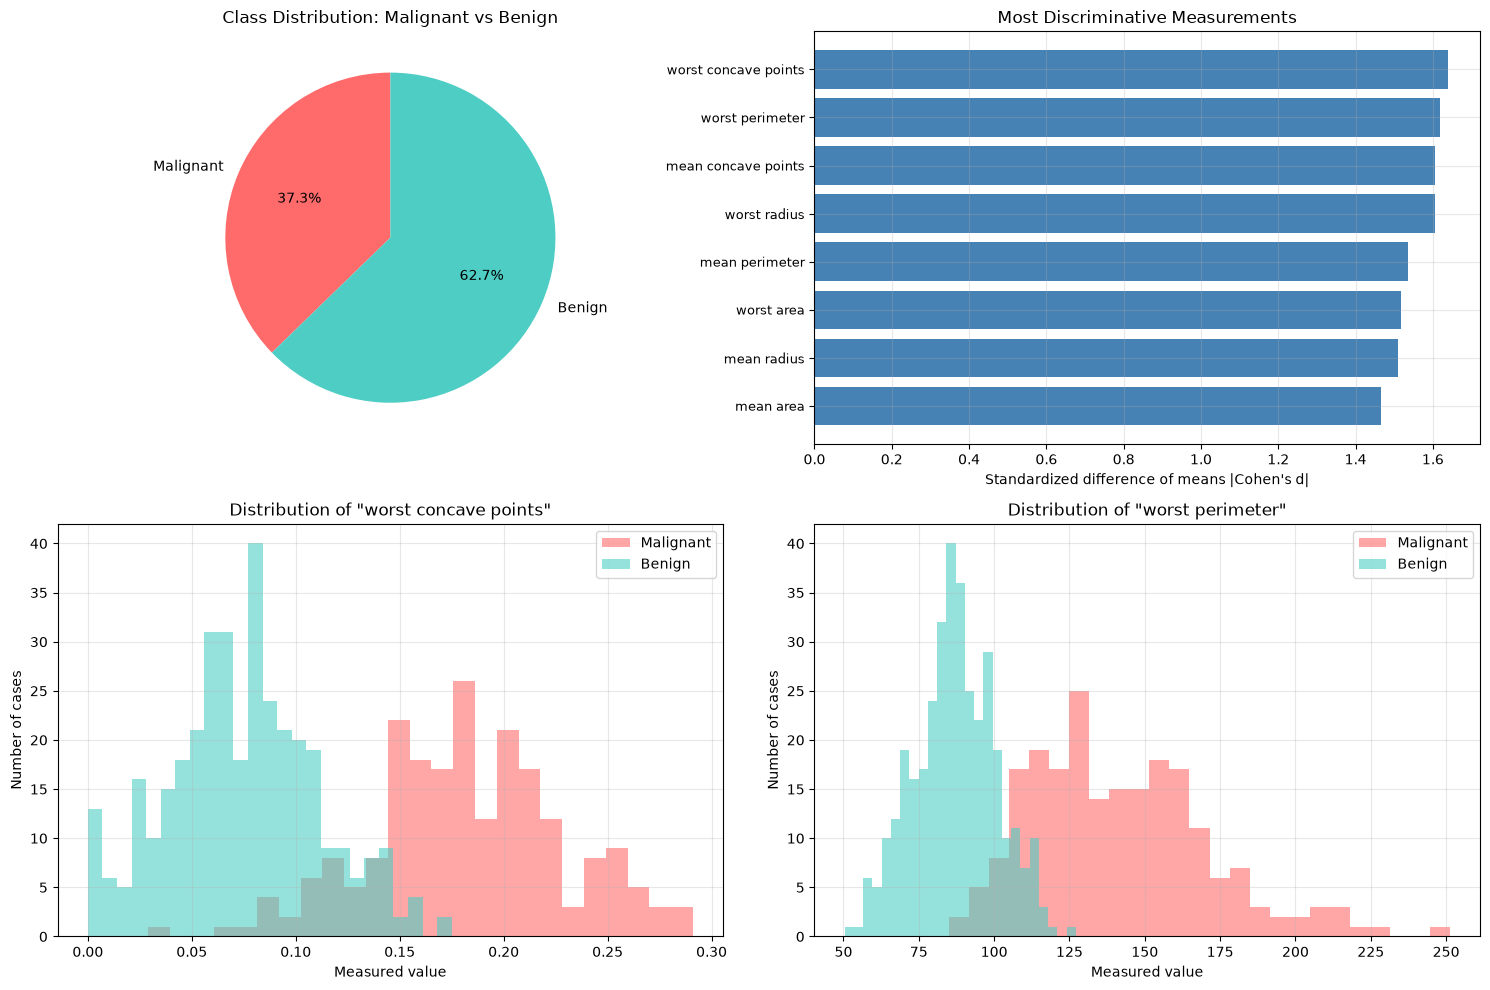

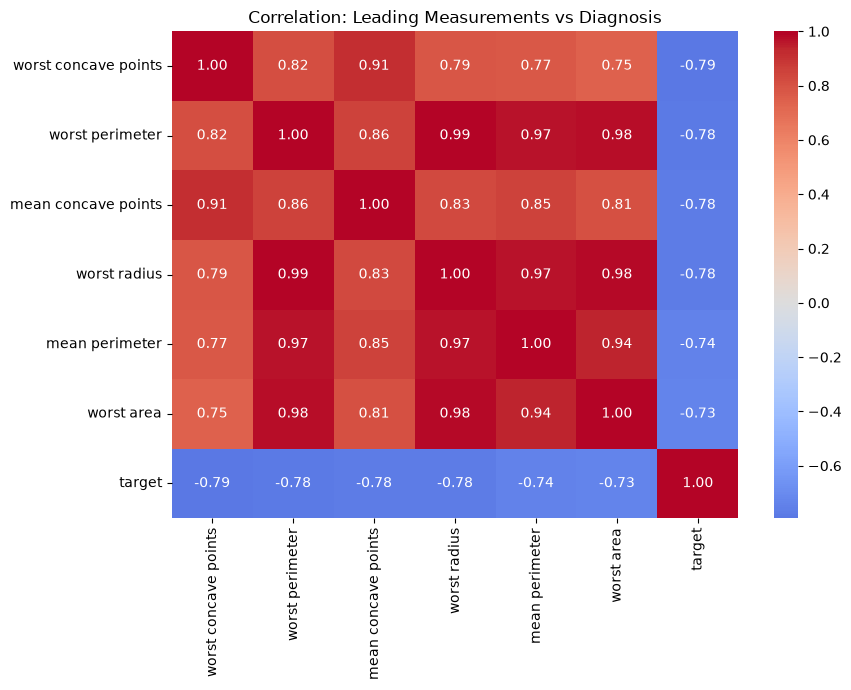


Key Insight: malignant nuclei are consistently larger and more irregular -
size measures (radius, perimeter, area) and shape measures (concavity,
concave points) separate the two groups most cleanly.
Note the strong correlation *between* those measurements: they describe the
same underlying biology, which is exactly the situation tree ensembles handle well.


In [5]:
# Exploratory Data Analysis for the diagnostic dataset
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

# Class distribution
axes[0,0].pie(np.bincount(y), labels=target_names, autopct='%1.1f%%', startangle=90,
              colors=['#ff6b6b', '#4ecdc4'])
axes[0,0].set_title('Class Distribution: Malignant vs Benign')

# Which features separate the classes best? Rank by standardized mean difference.
malignant = df[df['target'] == 0][feature_names]
benign = df[df['target'] == 1][feature_names]
pooled_sd = df[feature_names].std().replace(0, np.nan)
separation = ((malignant.mean() - benign.mean()) / pooled_sd).abs().sort_values(ascending=False)
top_features = list(separation.head(8).index)

axes[0,1].barh(range(len(top_features)), separation.head(8).values[::-1], color='steelblue')
axes[0,1].set_yticks(range(len(top_features)))
axes[0,1].set_yticklabels(top_features[::-1], fontsize=9)
axes[0,1].set_xlabel("Standardized difference of means |Cohen's d|")
axes[0,1].set_title('Most Discriminative Measurements')
axes[0,1].grid(True, alpha=0.3)

# Distribution of the two most discriminative features, malignant vs benign
for i, feat in enumerate(top_features[:2]):
    axes[1, i].hist(malignant[feat], alpha=0.6, label='Malignant', bins=25, color='#ff6b6b')
    axes[1, i].hist(benign[feat], alpha=0.6, label='Benign', bins=25, color='#4ecdc4')
    axes[1, i].set_title(f'Distribution of "{feat}"')
    axes[1, i].set_xlabel('Measured value')
    axes[1, i].set_ylabel('Number of cases')
    axes[1, i].legend()
    axes[1, i].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Correlation between the leading measurements and the diagnosis
plt.figure(figsize=(9, 7))
corr_subset = df[top_features[:6] + ['target']].corr()
sns.heatmap(corr_subset, annot=True, cmap='coolwarm', center=0, fmt='.2f')
plt.title('Correlation: Leading Measurements vs Diagnosis')
plt.tight_layout()
plt.show()

print("\nKey Insight: malignant nuclei are consistently larger and more irregular -")
print("size measures (radius, perimeter, area) and shape measures (concavity,")
print("concave points) separate the two groups most cleanly.")
print("Note the strong correlation *between* those measurements: they describe the")
print("same underlying biology, which is exactly the situation tree ensembles handle well.")


In [6]:
# Data preprocessing and train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set size: {X_train.shape}")
print(f"Test set size: {X_test.shape}")
print(f"Training class distribution: {np.bincount(y_train)}")
print(f"Test class distribution: {np.bincount(y_test)}")

Training set size: (455, 30)
Test set size: (114, 30)
Training class distribution: [170 285]
Test class distribution: [42 72]


In [7]:
# Train a basic XGBoost model
xgb_model = xgb.XGBClassifier(
    objective='binary:logistic',  # For binary classification
    random_state=42,
    eval_metric='logloss'  # Evaluation metric
)

# Fit the model
xgb_model.fit(X_train, y_train)

# Make predictions
y_pred = xgb_model.predict(X_test)
y_pred_proba = xgb_model.predict_proba(X_test)[:, 1]

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_pred_proba)

print(f"Accuracy: {accuracy:.4f}")
print(f"AUC-ROC: {auc:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=target_names))
print("\nClinical Context: the model sorts cases into Malignant (review first) and Benign.")
print("Sensitivity for 'Malignant' is what matters most - a malignant mass called benign")
print("is the error that delays treatment, and it is far costlier than a second look at a benign one.")


Accuracy: 0.9561
AUC-ROC: 0.9927

Classification Report:
              precision    recall  f1-score   support

   Malignant       0.97      0.90      0.94        42
      Benign       0.95      0.99      0.97        72

    accuracy                           0.96       114
   macro avg       0.96      0.95      0.95       114
weighted avg       0.96      0.96      0.96       114


Clinical Context: the model sorts cases into Malignant (review first) and Benign.
Sensitivity for 'Malignant' is what matters most - a malignant mass called benign
is the error that delays treatment, and it is far costlier than a second look at a benign one.


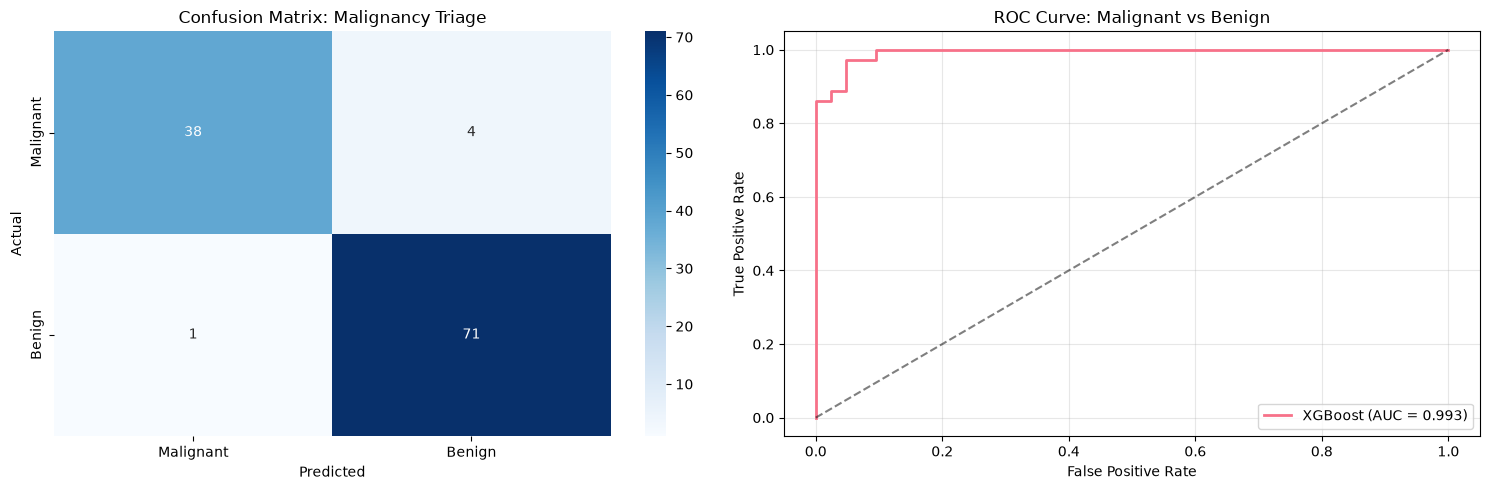

Confusion Matrix Interpretation for Clinical Review:
  - Benign correctly identified: 71
  - Malignant correctly identified: 38
  - Malignant called Benign: 4 - the costly miss, it delays treatment
  - Benign called Malignant: 1 - causes an unnecessary review, far cheaper


In [8]:
# Visualize results
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Confusion Matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=target_names, yticklabels=target_names, ax=axes[0])
axes[0].set_title('Confusion Matrix: Malignancy Triage')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# ROC Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
axes[1].plot(fpr, tpr, linewidth=2, label=f'XGBoost (AUC = {auc:.3f})')
axes[1].plot([0, 1], [0, 1], 'k--', alpha=0.5)
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].set_title('ROC Curve: Malignant vs Benign')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("Confusion Matrix Interpretation for Clinical Review:")
print(f"  - Benign correctly identified: {cm[1,1]}")
print(f"  - Malignant correctly identified: {cm[0,0]}")
print(f"  - Malignant called Benign: {cm[0,1]} - the costly miss, it delays treatment")
print(f"  - Benign called Malignant: {cm[1,0]} - causes an unnecessary review, far cheaper")


---
## 4. Key Parameters Deep Dive

Understanding XGBoost parameters is crucial for getting the best performance. Let's explore the most important ones.

### Main Categories of Parameters:

1. **Tree Structure Parameters**:
   - `max_depth`: Maximum depth of trees
   - `min_child_weight`: Minimum sum of instance weight in a child
   - `max_leaves`: Maximum number of leaves

2. **Learning Parameters**:
   - `learning_rate` (eta): Step size shrinkage
   - `n_estimators`: Number of boosting rounds
   - `subsample`: Subsample ratio of training instances
   - `colsample_bytree`: Subsample ratio of features

3. **Regularization Parameters**:
   - `reg_alpha`: L1 regularization term
   - `reg_lambda`: L2 regularization term
   - `gamma`: Minimum loss reduction for split

Let's see how these parameters affect model performance:

In [9]:
# # Function to evaluate model with different parameters
# def evaluate_xgb_params(X_train, X_test, y_train, y_test, **params):
#     model = xgb.XGBClassifier(random_state=42, **params)
#     model.fit(X_train, y_train)
    
#     y_pred = model.predict(X_test)
#     y_pred_proba = model.predict_proba(X_test)[:, 1]
    
#     accuracy = accuracy_score(y_test, y_pred)
#     auc = roc_auc_score(y_test, y_pred_proba)
    
#     return accuracy, auc, model

# # Test different learning rates
# learning_rates = [0.01, 0.05, 0.1, 0.2, 0.3]
# lr_results = []

# for lr in learning_rates:
#     acc, auc, _ = evaluate_xgb_params(X_train, X_test, y_train, y_test, 
#                                       learning_rate=lr, n_estimators=100)
#     lr_results.append((lr, acc, auc))
#     print(f"Learning Rate {lr:4.2f}: Accuracy={acc:.4f}, AUC={auc:.4f}")

# # Visualize learning rate impact
# lr_df = pd.DataFrame(lr_results, columns=['learning_rate', 'accuracy', 'auc'])

# fig, ax = plt.subplots(1, 1, figsize=(10, 6))
# ax2 = ax.twinx()

# ax.plot(lr_df['learning_rate'], lr_df['accuracy'], 'bo-', label='Accuracy')
# ax2.plot(lr_df['learning_rate'], lr_df['auc'], 'ro-', label='AUC')

# ax.set_xlabel('Learning Rate')
# ax.set_ylabel('Accuracy', color='b')
# ax2.set_ylabel('AUC', color='r')
# ax.set_title('Effect of Learning Rate on Model Performance')
# ax.grid(True, alpha=0.3)

# # Add legends
# lines1, labels1 = ax.get_legend_handles_labels()
# lines2, labels2 = ax2.get_legend_handles_labels()
# ax.legend(lines1 + lines2, labels1 + labels2, loc='best')

# plt.tight_layout()
# plt.show()

In [10]:
# Interactive parameter exploration
def interactive_xgb_demo(max_depth=6, learning_rate=0.1, n_estimators=100, subsample=1.0, reg_alpha=0.0):
    # Train model with specified parameters
    model = xgb.XGBClassifier(
        max_depth=max_depth,
        learning_rate=learning_rate,
        n_estimators=n_estimators,
        subsample=subsample,
        reg_alpha=reg_alpha,
        random_state=42
    )
    
    model.fit(X_train, y_train)
    
    # Predictions
    y_pred = model.predict(X_test)
    y_pred_proba = model.predict_proba(X_test)[:, 1]
    
    # Metrics
    accuracy = accuracy_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_pred_proba)
    
    # Feature importance
    feature_importance = model.feature_importances_
    
    # Create plots
    fig, axes = plt.subplots(1, 3, figsize=(20, 5))
    
    # ROC Curve
    fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
    axes[0].plot(fpr, tpr, linewidth=2)
    axes[0].plot([0, 1], [0, 1], 'k--', alpha=0.5)
    axes[0].set_xlabel('False Positive Rate')
    axes[0].set_ylabel('True Positive Rate')
    axes[0].set_title(f'ROC Curve (AUC = {auc:.3f})')
    axes[0].grid(True, alpha=0.3)
    
    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1],
                xticklabels=target_names, yticklabels=target_names)
    axes[1].set_title(f'Confusion Matrix (Acc = {accuracy:.3f})')
    
    # Top 10 Feature Importance (nuclear measurements)
    top_features = np.argsort(feature_importance)[-10:]
    axes[2].barh(range(len(top_features)), feature_importance[top_features])
    axes[2].set_yticks(range(len(top_features)))
    axes[2].set_yticklabels([feature_names[i] for i in top_features])
    axes[2].set_title('Top 10 Important Measurements')
    axes[2].set_xlabel('Importance')
    
    plt.tight_layout()
    plt.show()
    
    print(f"Model Parameters:")
    print(f"  max_depth: {max_depth}")
    print(f"  learning_rate: {learning_rate}")
    print(f"  n_estimators: {n_estimators}")
    print(f"  subsample: {subsample}")
    print(f"  reg_alpha: {reg_alpha}")
    print(f"\nDiagnostic Performance:")
    print(f"  Accuracy: {accuracy:.4f}")
    print(f"  AUC: {auc:.4f}")

# Create interactive widget
interact(interactive_xgb_demo,
         max_depth=IntSlider(value=6, min=1, max=10, description='Max Depth'),
         learning_rate=FloatSlider(value=0.1, min=0.01, max=0.3, step=0.01, description='Learning Rate'),
         n_estimators=IntSlider(value=100, min=10, max=300, step=10, description='N Estimators'),
         subsample=FloatSlider(value=1.0, min=0.5, max=1.0, step=0.1, description='Subsample'),
         reg_alpha=FloatSlider(value=0.0, min=0.0, max=1.0, step=0.1, description='Reg Alpha'));

interactive(children=(IntSlider(value=6, description='Max Depth', max=10, min=1), FloatSlider(value=0.1, descr…

### Parameter Tuning Guidelines:

**For High Variance (Overfitting):**
- Increase regularization (`reg_alpha`, `reg_lambda`)
- Decrease `max_depth`
- Increase `min_child_weight`
- Decrease `learning_rate` and increase `n_estimators`
- Use subsampling (`subsample < 1.0`, `colsample_bytree < 1.0`)

**For High Bias (Underfitting):**
- Increase `max_depth`
- Decrease `min_child_weight`
- Increase `learning_rate`
- Increase `n_estimators`
- Decrease regularization

---
## 5. Advanced Features

XGBoost offers several advanced features that make it particularly powerful in practice.

### 5.1 Handling Missing Values

XGBoost automatically learns the optimal direction to handle missing values during training.

In [11]:
# Create a dataset with missing values
X_missing = X_train.copy()
np.random.seed(42)

# Randomly introduce missing values (10% of data)
missing_mask = np.random.random(X_missing.shape) < 0.1
X_missing[missing_mask] = np.nan

print(f"Missing values introduced: {np.sum(missing_mask)} ({np.sum(missing_mask)/X_missing.size*100:.1f}%)")
print(f"Features with missing values: {np.sum(np.isnan(X_missing).any(axis=0))}")

# Train XGBoost on data with missing values
xgb_missing = xgb.XGBClassifier(random_state=42)
xgb_missing.fit(X_missing, y_train)

# Introduce missing values to test set too
X_test_missing = X_test.copy()
missing_mask_test = np.random.random(X_test_missing.shape) < 0.1
X_test_missing[missing_mask_test] = np.nan

# Make predictions
y_pred_missing = xgb_missing.predict(X_test_missing)
accuracy_missing = accuracy_score(y_test, y_pred_missing)

print(f"\nAccuracy with missing values: {accuracy_missing:.4f}")
print(f"Accuracy without missing values: {accuracy:.4f}")
print(f"Performance drop: {(accuracy - accuracy_missing)*100:.2f} percentage points")

Missing values introduced: 1386 (10.2%)
Features with missing values: 30

Accuracy with missing values: 0.9386
Accuracy without missing values: 0.9561
Performance drop: 1.75 percentage points


### 5.2 Early Stopping

Early stopping prevents overfitting by monitoring validation performance and stopping when it stops improving.

In [12]:
# Split training data to create a validation set
X_train_es, X_val_es, y_train_es, y_val_es = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42, stratify=y_train
)

# Train with early stopping
xgb_early_stop = xgb.XGBClassifier(
    n_estimators=1000,  # Large number
    learning_rate=0.05,
    random_state=42,
    callbacks=[xgb.callback.EarlyStopping(rounds=10, save_best=True)]  # Updated syntax
)

xgb_early_stop.fit(
    X_train_es, y_train_es,
    eval_set=[(X_val_es, y_val_es)],
    verbose=False
)

print(f"Best iteration: {xgb_early_stop.best_iteration}")
print(f"Best score: {xgb_early_stop.best_score:.4f}")

# Compare with and without early stopping
xgb_no_early_stop = xgb.XGBClassifier(
    n_estimators=xgb_early_stop.best_iteration * 3,  # Train much longer
    learning_rate=0.05,
    random_state=42
)
xgb_no_early_stop.fit(X_train_es, y_train_es)

# Evaluate both
y_pred_es = xgb_early_stop.predict(X_test)
y_pred_no_es = xgb_no_early_stop.predict(X_test)

acc_es = accuracy_score(y_test, y_pred_es)
acc_no_es = accuracy_score(y_test, y_pred_no_es)

print(f"\nTest Accuracy:")
print(f"  With early stopping: {acc_es:.4f}")
print(f"  Without early stopping: {acc_no_es:.4f}")
print(f"  Training time saved: ~{(1 - xgb_early_stop.best_iteration/(xgb_early_stop.best_iteration*3))*100:.0f}%")

Best iteration: 67
Best score: 0.1537



Test Accuracy:
  With early stopping: 0.9386
  Without early stopping: 0.9386
  Training time saved: ~67%


### 5.3 Cross-Validation with XGBoost

XGBoost provides built-in cross-validation functionality.

Best CV AUC: 0.9935 ± 0.0042
Best iteration: 48


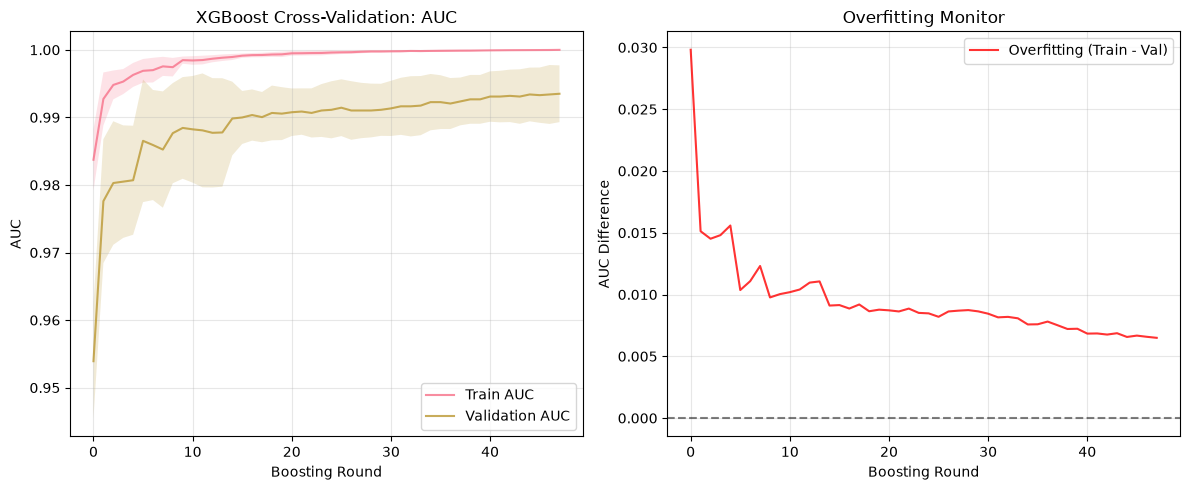

In [13]:
# Prepare data in DMatrix format for XGBoost CV
dtrain = xgb.DMatrix(X_train, label=y_train)

# Set parameters
params = {
    'objective': 'binary:logistic',
    'eval_metric': 'auc',
    'max_depth': 6,
    'learning_rate': 0.1,
    'subsample': 0.8,
    'colsample_bytree': 0.8,
    'seed': 42
}

# Perform cross-validation
cv_results = xgb.cv(
    params=params,
    dtrain=dtrain,
    num_boost_round=200,
    nfold=5,
    stratified=True,
    early_stopping_rounds=10,
    seed=42,
    verbose_eval=False
)

print(f"Best CV AUC: {cv_results['test-auc-mean'].max():.4f} ± {cv_results['test-auc-std'][cv_results['test-auc-mean'].idxmax()]:.4f}")
print(f"Best iteration: {cv_results['test-auc-mean'].idxmax() + 1}")

# Plot CV results
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(cv_results['train-auc-mean'], label='Train AUC', alpha=0.8)
plt.plot(cv_results['test-auc-mean'], label='Validation AUC', alpha=0.8)
plt.fill_between(range(len(cv_results)), 
                 cv_results['train-auc-mean'] - cv_results['train-auc-std'],
                 cv_results['train-auc-mean'] + cv_results['train-auc-std'],
                 alpha=0.2)
plt.fill_between(range(len(cv_results)), 
                 cv_results['test-auc-mean'] - cv_results['test-auc-std'],
                 cv_results['test-auc-mean'] + cv_results['test-auc-std'],
                 alpha=0.2)
plt.xlabel('Boosting Round')
plt.ylabel('AUC')
plt.title('XGBoost Cross-Validation: AUC')
plt.legend()
plt.grid(True, alpha=0.3)

# Show difference between train and validation
plt.subplot(1, 2, 2)
overfitting = cv_results['train-auc-mean'] - cv_results['test-auc-mean']
plt.plot(overfitting, label='Overfitting (Train - Val)', color='red', alpha=0.8)
plt.axhline(y=0, color='black', linestyle='--', alpha=0.5)
plt.xlabel('Boosting Round')
plt.ylabel('AUC Difference')
plt.title('Overfitting Monitor')
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### 5.4 Custom Evaluation Metrics

You can define custom evaluation metrics for specific business needs.

In [14]:
# Custom evaluation metric: F1 Score
def f1_eval(y_pred, dtrain):
    y_true = dtrain.get_label()
    y_pred_binary = (y_pred > 0.5).astype(int)
    
    tp = np.sum((y_true == 1) & (y_pred_binary == 1))
    fp = np.sum((y_true == 0) & (y_pred_binary == 1))
    fn = np.sum((y_true == 1) & (y_pred_binary == 0))
    
    precision = tp / (tp + fp) if (tp + fp) > 0 else 0
    recall = tp / (tp + fn) if (tp + fn) > 0 else 0
    f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
    
    return 'f1', f1

# Train with custom metric using sklearn wrapper (simpler approach)
xgb_custom = xgb.XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)

# Train the model
xgb_custom.fit(X_train, y_train)

# Calculate F1 score manually for demonstration
from sklearn.metrics import f1_score
y_pred_custom = xgb_custom.predict(X_test)
f1_custom = f1_score(y_test, y_pred_custom)

print("Training completed with XGBoost classifier")
print(f"F1 Score on test set: {f1_custom:.4f}")
print("For custom evaluation metrics during training, you can:")
print("1. Use sklearn's scoring parameter in GridSearchCV")
print("2. Monitor custom metrics after each training iteration")
print("3. Use callbacks for more advanced custom evaluation")

Training completed with XGBoost classifier
F1 Score on test set: 0.9589
For custom evaluation metrics during training, you can:
1. Use sklearn's scoring parameter in GridSearchCV
2. Monitor custom metrics after each training iteration
3. Use callbacks for more advanced custom evaluation


---
## 6. Model Interpretation with SHAP

Understanding why your model makes specific predictions is crucial, especially in high-stakes domains. SHAP (SHapley Additive exPlanations) provides a unified approach to explain model predictions.

In [15]:
# Train a model for SHAP analysis
shap_model = xgb.XGBClassifier(
    max_depth=4,
    n_estimators=100,
    learning_rate=0.1,
    random_state=42
)
shap_model.fit(X_train, y_train)

# Explain the test set. Passing a named DataFrame means every SHAP plot below
# is labelled with the actual measurement, not "Feature 17".
X_test_df = pd.DataFrame(X_test, columns=feature_names)

explainer = shap.Explainer(shap_model)
shap_values = explainer(X_test_df)  # Explain all test samples

print(f"SHAP values computed for {len(shap_values)} biopsy cases")
print(f"Feature names: {feature_names[:5]}...")  # Show first 5 measurements
print("\nSHAP analysis will reveal which nuclear measurements matter most")
print("when the model separates malignant from benign masses.")


SHAP values computed for 114 biopsy cases
Feature names: [np.str_('mean radius'), np.str_('mean texture'), np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean smoothness')]...

SHAP analysis will reveal which nuclear measurements matter most
when the model separates malignant from benign masses.


/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85203/1824559621.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_df, feature_names=feature_names, show=False)


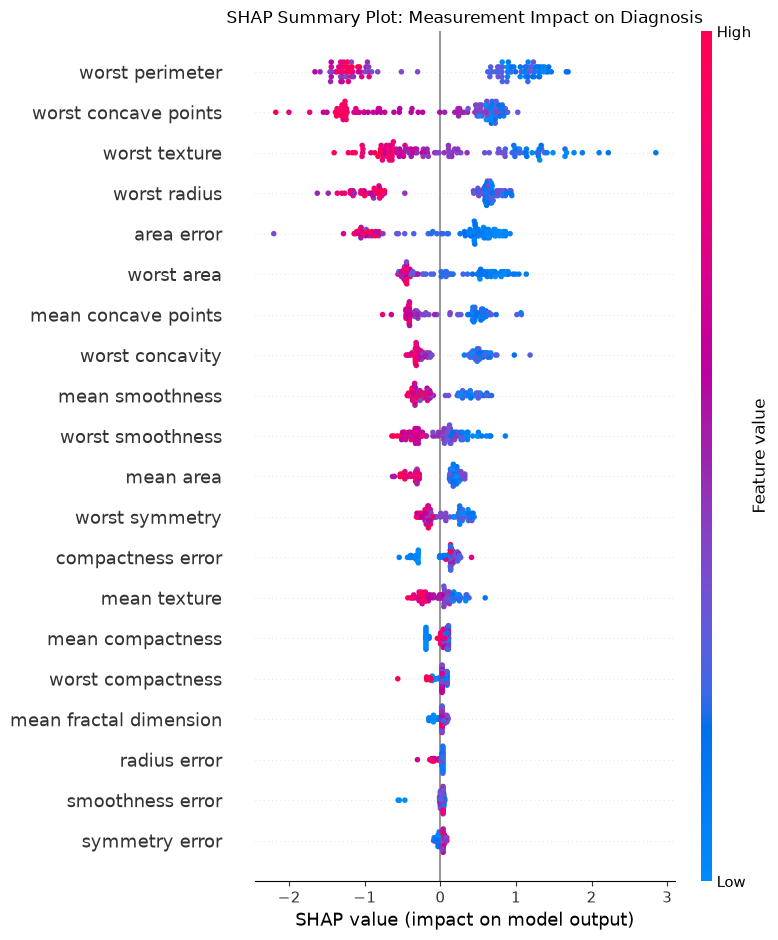

Interpretation for Clinical Review:
- Each dot represents one case
- X-axis shows SHAP value (impact on classification)
- Color indicates the measured value (red=high, blue=low)
- Measurements are ranked by importance (top to bottom)

Top 10 Most Important Measurements for the Diagnosis:
1. worst perimeter (importance: 1.1263)
2. worst concave points (importance: 0.7993)
3. worst texture (importance: 0.7846)
4. worst radius (importance: 0.7741)
5. area error (importance: 0.6667)
6. worst area (importance: 0.5027)
7. mean concave points (importance: 0.4474)
8. worst concavity (importance: 0.4117)
9. mean smoothness (importance: 0.3168)
10. worst smoothness (importance: 0.2773)


In [16]:
# SHAP Summary Plot - shows feature importance and impact direction
plt.figure(figsize=(12, 10))
shap.summary_plot(shap_values, X_test_df, feature_names=feature_names, show=False)
plt.title('SHAP Summary Plot: Measurement Impact on Diagnosis')
plt.tight_layout()
plt.show()

print("Interpretation for Clinical Review:")
print("- Each dot represents one case")
print("- X-axis shows SHAP value (impact on classification)")
print("- Color indicates the measured value (red=high, blue=low)")
print("- Measurements are ranked by importance (top to bottom)")

# Also show the top 10 most important measurements by name
feature_importance = np.abs(shap_values.values).mean(0)
top_10_indices = np.argsort(feature_importance)[-10:]
print(f"\nTop 10 Most Important Measurements for the Diagnosis:")
for i, idx in enumerate(reversed(top_10_indices)):
    print(f"{i+1}. {feature_names[idx]} (importance: {feature_importance[idx]:.4f})")


/var/folders/j1/63cpknxj4sl05j90p4w75mb00000gn/T/ipykernel_85203/286181021.py:3: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(shap_values, X_test_df, plot_type="bar", feature_names=feature_names, show=False)


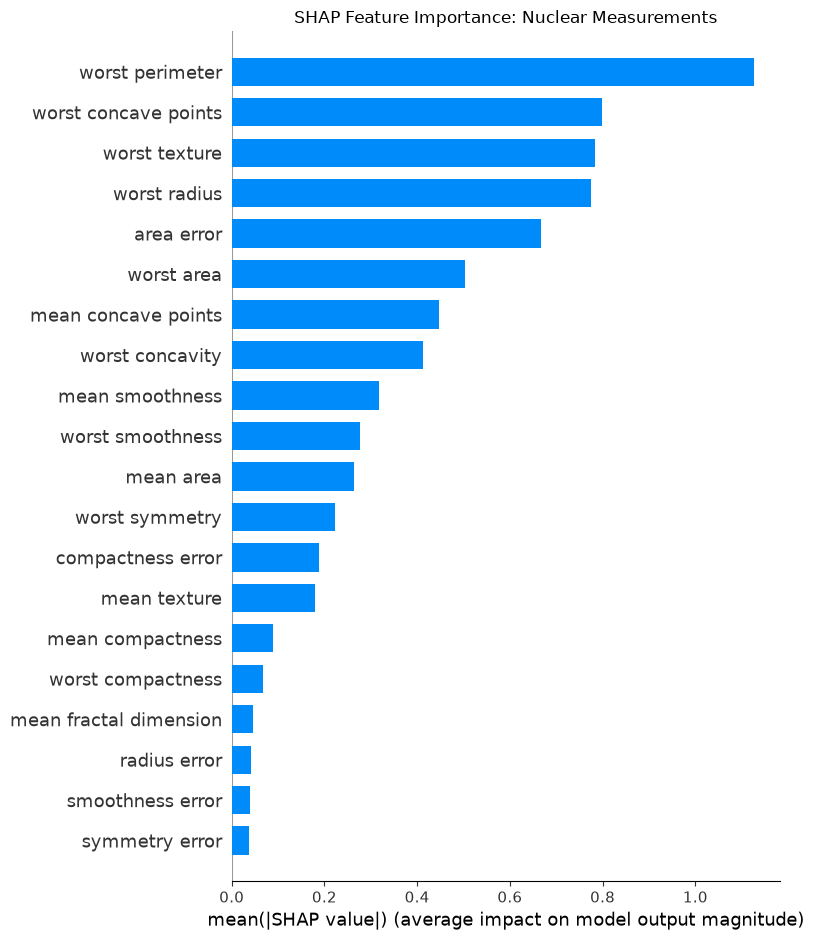

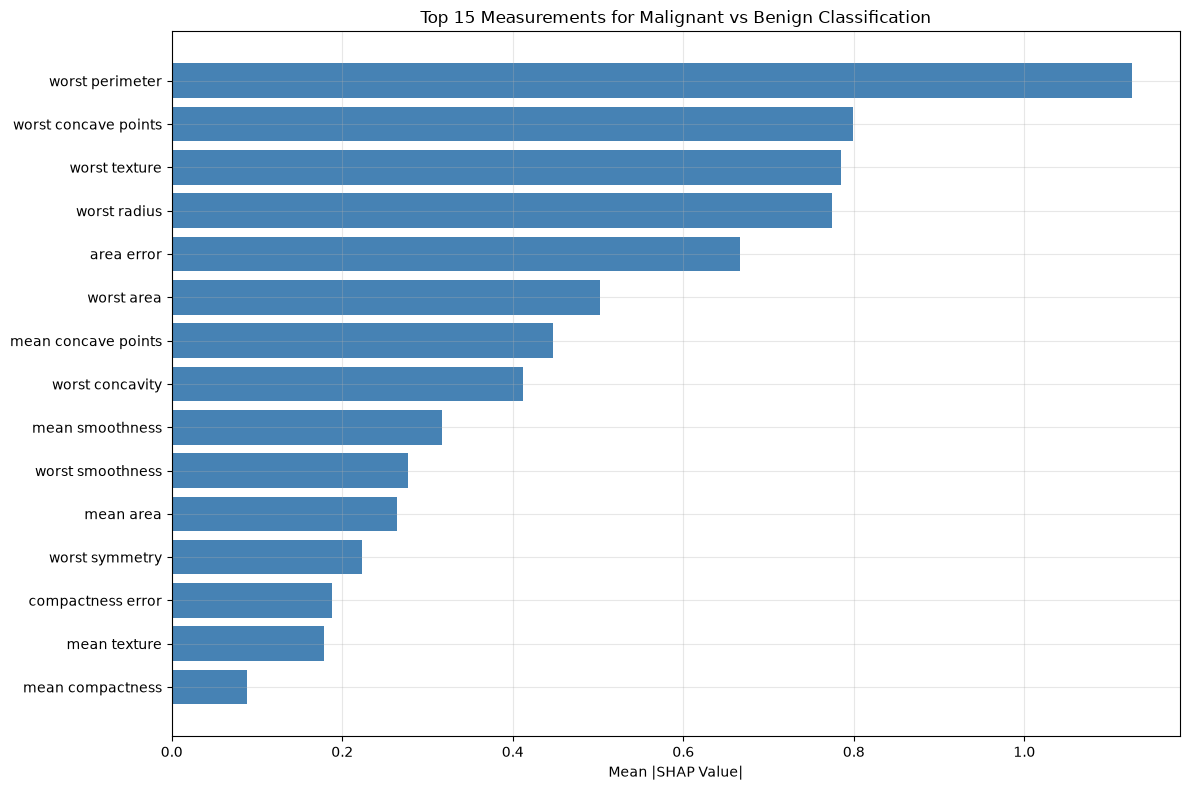

Clinical Insight:
These measurements carry most of the model's discriminative power.
Because they are named and physically meaningful, a pathologist can check the
model's reasoning against what they already know about nuclear morphology.


In [17]:
# SHAP Bar Plot - shows feature importance
plt.figure(figsize=(12, 8))
shap.summary_plot(shap_values, X_test_df, plot_type="bar", feature_names=feature_names, show=False)
plt.title('SHAP Feature Importance: Nuclear Measurements')
plt.tight_layout()
plt.show()

# Alternative visualization for clarity
feature_importance = np.abs(shap_values.values).mean(0)
top_15_indices = np.argsort(feature_importance)[-15:]

plt.figure(figsize=(12, 8))
plt.barh(range(len(top_15_indices)), feature_importance[top_15_indices], color='steelblue')
plt.yticks(range(len(top_15_indices)), [feature_names[i] for i in top_15_indices])
plt.xlabel('Mean |SHAP Value|')
plt.title('Top 15 Measurements for Malignant vs Benign Classification')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Clinical Insight:")
print("These measurements carry most of the model's discriminative power.")
print("Because they are named and physically meaningful, a pathologist can check the")
print("model's reasoning against what they already know about nuclear morphology.")


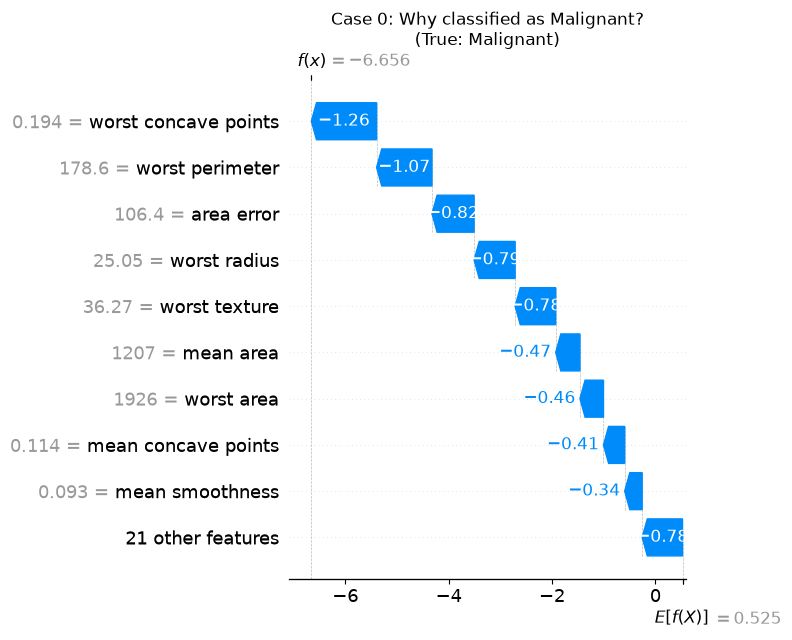

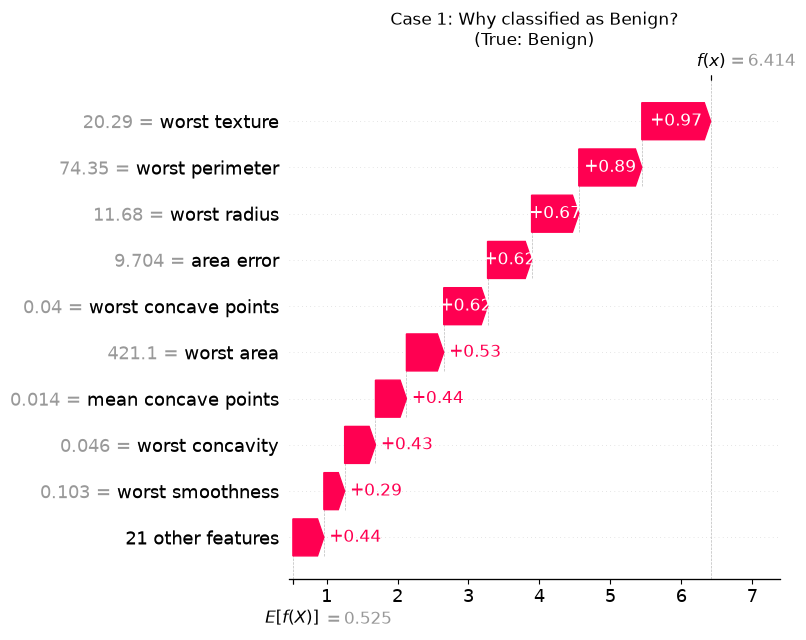


Waterfall Plot Interpretation for Clinical Review:
- Starts with base value (expected model output)
- Each bar shows how one measurement pushes the prediction up/down
- Final value is the model's output for this case
- Red bars push towards 'Benign'
- Blue bars push towards 'Malignant'

Clinical Value: it shows WHY a case was placed high or low in the review queue,
which is what lets a pathologist agree or disagree with the ranking on the spot.


In [18]:
# Explain individual case classifications
# Select a few interesting samples
sample_indices = [0, 1, 10, 20]  # Different cases to explain

for i, idx in enumerate(sample_indices[:2]):  # Show 2 examples
    # SHAP waterfall plot for individual prediction
    plt.figure(figsize=(10, 6))
    shap.waterfall_plot(shap_values[idx], show=False)

    true_label = target_names[y_test[idx]]
    pred_label = target_names[shap_model.predict(X_test[idx].reshape(1, -1))[0]]

    plt.title(f'Case {idx}: Why classified as {pred_label}?\n(True: {true_label})')
    plt.tight_layout()
    plt.show()

print("\nWaterfall Plot Interpretation for Clinical Review:")
print("- Starts with base value (expected model output)")
print("- Each bar shows how one measurement pushes the prediction up/down")
print("- Final value is the model's output for this case")
print("- Red bars push towards 'Benign'")
print("- Blue bars push towards 'Malignant'")
print("\nClinical Value: it shows WHY a case was placed high or low in the review queue,")
print("which is what lets a pathologist agree or disagree with the ranking on the spot.")


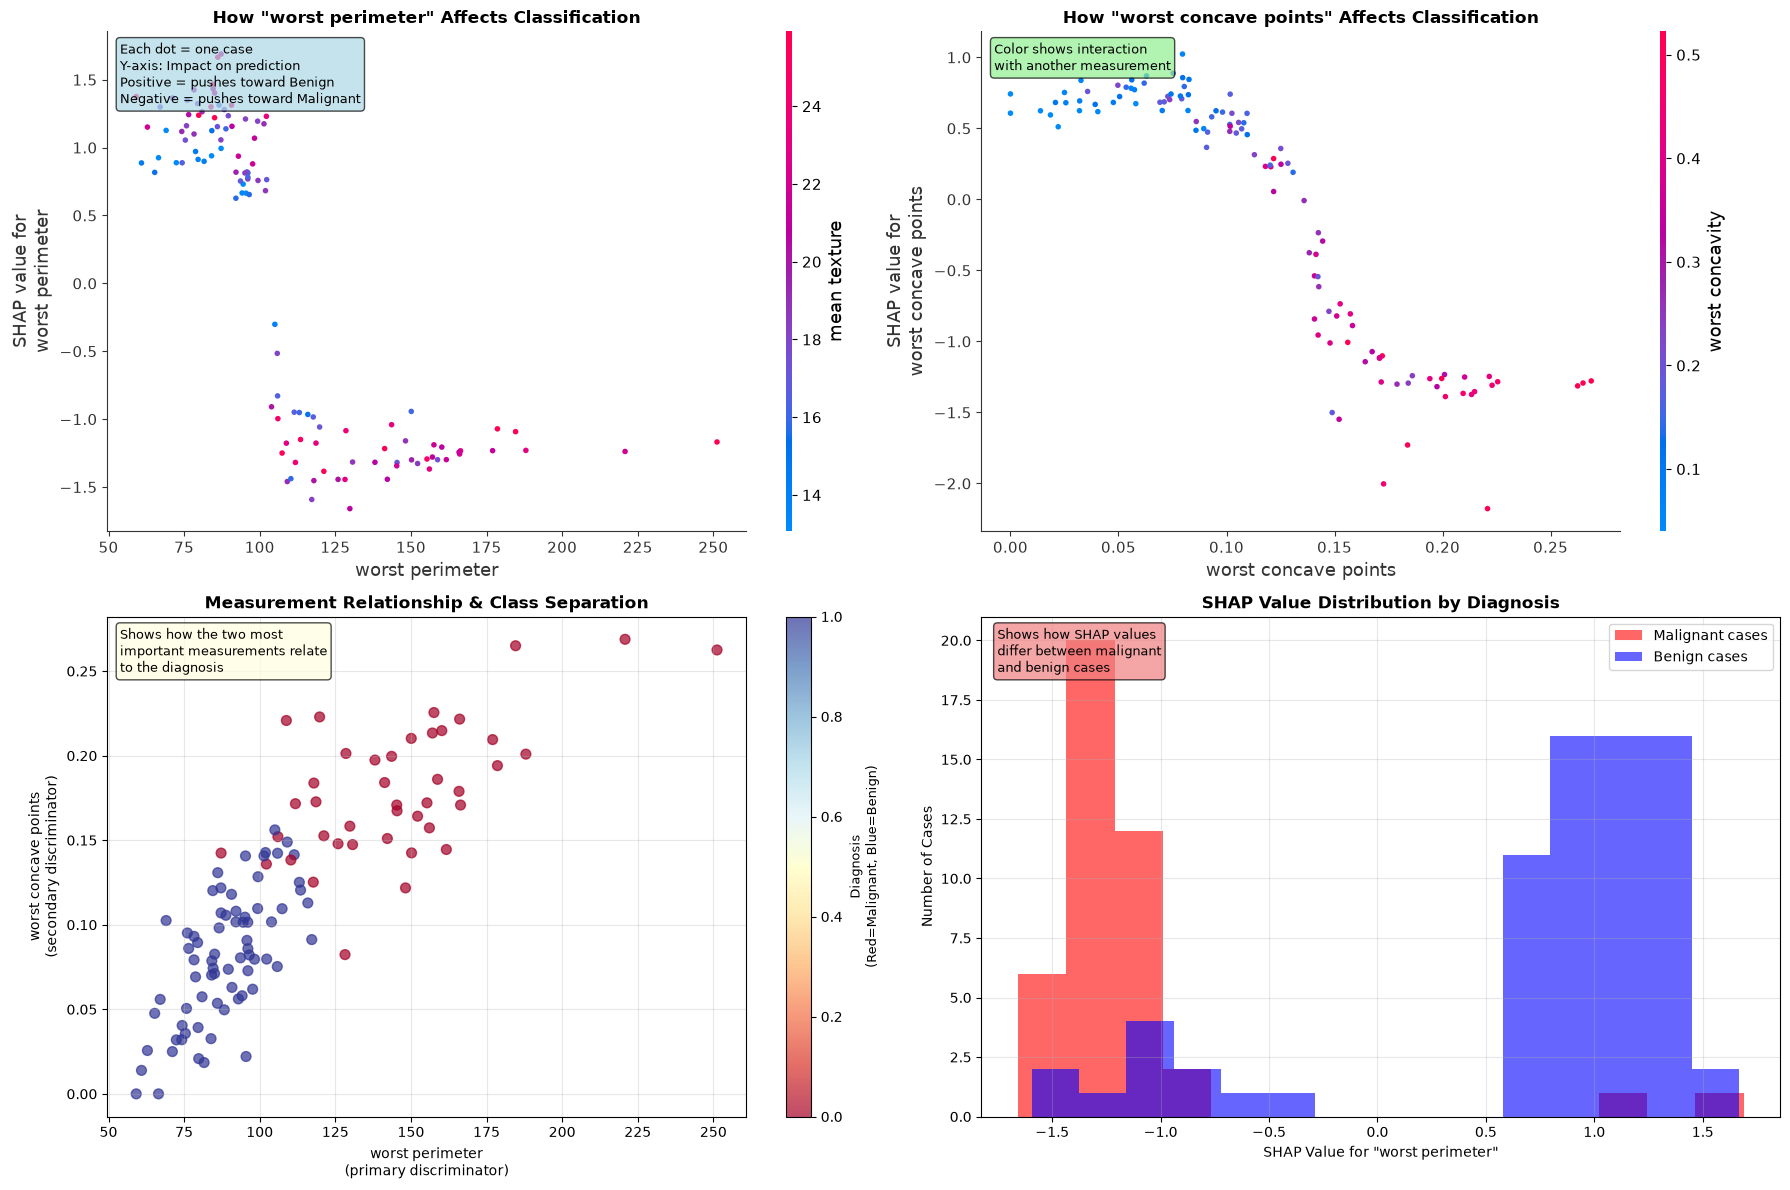

DETAILED INTERPRETATION FOR CLINICAL REVIEW:

SHAP Dependence Plots Explained:
- TOP-LEFT: How 'worst perimeter' affects the classification
- TOP-RIGHT: How 'worst concave points' affects the classification
- X-axis: the measured value
- Y-axis: SHAP value = impact on the classification decision
  - Positive SHAP values -> pushes toward BENIGN
  - Negative SHAP values -> pushes toward MALIGNANT

Key Findings:
1. worst perimeter (importance: 1.1263)
   - The single most discriminative measurement in this model

2. worst concave points (importance: 0.7993)
   - The second most discriminative measurement

WHAT THIS MEANS:
- For MALIGNANT cases, 'worst perimeter' has avg SHAP: -1.122
- For BENIGN cases, 'worst perimeter' has avg SHAP: 0.746
- Malignant masses sit at values of this measurement that push toward malignancy
- This matches the pathology: malignant nuclei are larger and more irregular

CLINICAL APPLICATION:
1. The model ranks cases so the most concerning slides are reviewed firs

In [19]:
# SHAP Dependence Plot - shows how individual measurements affect predictions
feature_importance = np.abs(shap_values.values).mean(0)
most_important_feature_idx = int(np.argmax(feature_importance))
most_important_feature = feature_names[most_important_feature_idx]

# Get second most important feature
second_important_idx = int(np.argsort(feature_importance)[-2])
second_important_feature = feature_names[second_important_idx]

# Create figure with explicit subplots
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(18, 12))

# First dependence plot
try:
    shap.dependence_plot(most_important_feature_idx, shap_values.values, X_test,
                         feature_names=feature_names, show=False, ax=ax1)
    ax1.set_title(f'How "{most_important_feature}" Affects Classification', fontsize=12, fontweight='bold')
except Exception:
    ax1.scatter(X_test[:, most_important_feature_idx], shap_values.values[:, most_important_feature_idx], alpha=0.6, c='blue')
    ax1.set_xlabel(f'{most_important_feature}\n(measured value)', fontsize=10)
    ax1.set_ylabel('SHAP Value\n(+ pushes toward Benign, - toward Malignant)', fontsize=10)
    ax1.set_title(f'How "{most_important_feature}" Affects Classification', fontsize=12, fontweight='bold')
    ax1.grid(True, alpha=0.3)

ax1.text(0.02, 0.98, 'Each dot = one case\nY-axis: Impact on prediction\nPositive = pushes toward Benign\nNegative = pushes toward Malignant',
         transform=ax1.transAxes, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='lightblue', alpha=0.7), fontsize=9)

# Second dependence plot
try:
    shap.dependence_plot(second_important_idx, shap_values.values, X_test,
                         feature_names=feature_names, show=False, ax=ax2)
    ax2.set_title(f'How "{second_important_feature}" Affects Classification', fontsize=12, fontweight='bold')
except Exception:
    ax2.scatter(X_test[:, second_important_idx], shap_values.values[:, second_important_idx], alpha=0.6, c='green')
    ax2.set_xlabel(f'{second_important_feature}\n(measured value)', fontsize=10)
    ax2.set_ylabel('SHAP Value\n(+ pushes toward Benign, - toward Malignant)', fontsize=10)
    ax2.set_title(f'How "{second_important_feature}" Affects Classification', fontsize=12, fontweight='bold')
    ax2.grid(True, alpha=0.3)

ax2.text(0.02, 0.98, 'Color shows interaction\nwith another measurement',
         transform=ax2.transAxes, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='lightgreen', alpha=0.7), fontsize=9)

# Feature relationship with class separation
scatter = ax3.scatter(X_test[:, most_important_feature_idx], X_test[:, second_important_idx],
                     c=y_test, cmap='RdYlBu', alpha=0.7, s=50)
ax3.set_xlabel(f'{most_important_feature}\n(primary discriminator)', fontsize=10)
ax3.set_ylabel(f'{second_important_feature}\n(secondary discriminator)', fontsize=10)
ax3.set_title('Measurement Relationship & Class Separation', fontsize=12, fontweight='bold')
cbar = plt.colorbar(scatter, ax=ax3)
cbar.set_label('Diagnosis\n(Red=Malignant, Blue=Benign)', fontsize=9)
ax3.grid(True, alpha=0.3)

ax3.text(0.02, 0.98, 'Shows how the two most\nimportant measurements relate\nto the diagnosis',
         transform=ax3.transAxes, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='lightyellow', alpha=0.7), fontsize=9)

# SHAP value distribution by class
malignant_shap = shap_values.values[y_test == 0, most_important_feature_idx]
benign_shap = shap_values.values[y_test == 1, most_important_feature_idx]

ax4.hist(malignant_shap, alpha=0.6, label='Malignant cases', color='red', bins=15)
ax4.hist(benign_shap, alpha=0.6, label='Benign cases', color='blue', bins=15)
ax4.set_xlabel(f'SHAP Value for "{most_important_feature}"', fontsize=10)
ax4.set_ylabel('Number of Cases', fontsize=10)
ax4.set_title('SHAP Value Distribution by Diagnosis', fontsize=12, fontweight='bold')
ax4.legend()
ax4.grid(True, alpha=0.3)

ax4.text(0.02, 0.98, 'Shows how SHAP values\ndiffer between malignant\nand benign cases',
         transform=ax4.transAxes, verticalalignment='top', bbox=dict(boxstyle='round', facecolor='lightcoral', alpha=0.7), fontsize=9)

plt.tight_layout()
plt.show()

# Comprehensive interpretation for the clinical context
print("DETAILED INTERPRETATION FOR CLINICAL REVIEW:")
print("=" * 55)

print(f"\nSHAP Dependence Plots Explained:")
print(f"- TOP-LEFT: How '{most_important_feature}' affects the classification")
print(f"- TOP-RIGHT: How '{second_important_feature}' affects the classification")
print(f"- X-axis: the measured value")
print(f"- Y-axis: SHAP value = impact on the classification decision")
print(f"  - Positive SHAP values -> pushes toward BENIGN")
print(f"  - Negative SHAP values -> pushes toward MALIGNANT")

print(f"\nKey Findings:")
print(f"1. {most_important_feature} (importance: {feature_importance[most_important_feature_idx]:.4f})")
print(f"   - The single most discriminative measurement in this model")

print(f"\n2. {second_important_feature} (importance: {feature_importance[second_important_idx]:.4f})")
print(f"   - The second most discriminative measurement")

# Practical interpretation
malignant_mean_shap = np.mean(malignant_shap) if len(malignant_shap) > 0 else 0
benign_mean_shap = np.mean(benign_shap) if len(benign_shap) > 0 else 0

print(f"\nWHAT THIS MEANS:")
print(f"- For MALIGNANT cases, '{most_important_feature}' has avg SHAP: {malignant_mean_shap:.3f}")
print(f"- For BENIGN cases, '{most_important_feature}' has avg SHAP: {benign_mean_shap:.3f}")

if malignant_mean_shap < benign_mean_shap:
    print(f"- Malignant masses sit at values of this measurement that push toward malignancy")
    print(f"- This matches the pathology: malignant nuclei are larger and more irregular")
else:
    print(f"- The direction of this measurement's effect is worth checking against pathology")
    print(f"- A model whose reasoning contradicts known biology should not be trusted")

print(f"\nCLINICAL APPLICATION:")
print(f"1. The model ranks cases so the most concerning slides are reviewed first")
print(f"2. SHAP shows which measurements drove each ranking")
print(f"3. Understanding WHY a case was flagged is what earns clinician trust")
print(f"4. Measurements the model leans on can be prioritized for quality control")


---
## 7. Comparison with Other Algorithms

Let's compare XGBoost with other popular algorithms to understand when to use each one.

In [20]:
import time
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline

# Define models to compare
models = {
    'Logistic Regression': Pipeline([
        ('scaler', StandardScaler()),
        ('lr', LogisticRegression(random_state=42, max_iter=2000, solver='lbfgs'))
    ]),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(n_estimators=100, random_state=42),
    'XGBoost': xgb.XGBClassifier(n_estimators=100, random_state=42),
    'SVM': Pipeline([
        ('scaler', StandardScaler()),
        ('svm', SVC(probability=True, random_state=42))
    ]),
    'Naive Bayes': GaussianNB()
}

# Compare models
results = []

for name, model in models.items():
    # Time the training
    start_time = time.time()
    model.fit(X_train, y_train)
    training_time = time.time() - start_time
    
    # Time the prediction
    start_time = time.time()
    y_pred = model.predict(X_test)
    prediction_time = time.time() - start_time
    
    # Calculate metrics
    accuracy = accuracy_score(y_test, y_pred)
    
    # AUC (if model supports probability prediction)
    try:
        y_pred_proba = model.predict_proba(X_test)[:, 1]
        auc = roc_auc_score(y_test, y_pred_proba)
    except:
        auc = np.nan
    
    results.append({
        'Model': name,
        'Accuracy': accuracy,
        'AUC': auc,
        'Training Time (s)': training_time,
        'Prediction Time (s)': prediction_time
    })

# Convert to DataFrame for better visualization
results_df = pd.DataFrame(results)
print("Model Comparison Results:")
print(results_df.round(4))

print("\nNote: Logistic Regression and SVM now use StandardScaler preprocessing for better performance.")

Model Comparison Results:
                 Model  Accuracy     AUC  Training Time (s)  \
0  Logistic Regression    0.9825  0.9954             0.0036   
1        Random Forest    0.9561  0.9937             0.0723   
2    Gradient Boosting    0.9561  0.9907             0.1846   
3              XGBoost    0.9561  0.9927             0.1052   
4                  SVM    0.9825  0.9950             0.0072   
5          Naive Bayes    0.9386  0.9878             0.0004   

   Prediction Time (s)  
0               0.0002  
1               0.0027  
2               0.0003  
3               0.0006  
4               0.0007  
5               0.0001  

Note: Logistic Regression and SVM now use StandardScaler preprocessing for better performance.


/Users/randygiffen/.venvs/ai-fundamentals-healthcare/lib/python3.12/site-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


These results reveal important insights about the diagnostic dataset and algorithm behaviour.

## Why Different Algorithms May Perform Differently on This Data

### 1. Dataset Characteristics

The Breast Cancer Wisconsin dataset has particular properties:
- **30 continuous features**: every feature is a morphometric measurement of cell nuclei
- **Relatively small**: 569 cases, which can make some algorithms prone to overfitting
- **Heavily correlated features**: radius, perimeter and area describe the same object three ways, and each of the ten properties appears as a mean, an error and a "worst" value

### 2. Algorithm Suitability

**Tree-based methods (XGBoost, Random Forest):**
- Excel at capturing non-linear thresholds in the measurements
- Can identify the cut-points clinicians themselves reason with ("worst concave points above X")
- Handle the correlated feature groups well

**Linear models (Logistic Regression):**
- Actually do well here, because malignancy separates fairly cleanly on size and shape
- Need feature scaling, since area is measured in the thousands and smoothness near zero

**SVM:**
- Good for data with many correlated dimensions
- RBF kernel can capture non-linear boundaries
- Sensitive to proper scaling

### 3. Clinical Perspective

For a case-review queue, we care about:
- **High sensitivity for malignancy**: a malignant mass called benign delays treatment
- **Reasonable precision**: too many false alarms waste pathologist time and erode trust
- **Model interpretability**: a clinician has to be able to see the reasoning

### Key Takeaways for Clinical Applications

1. **XGBoost** provides a good balance of accuracy and interpretability
2. **SHAP values** reveal which measurements are most diagnostic
3. **Model selection** should weigh the cost of a missed malignancy against a false alarm, not just accuracy
4. **Ensemble methods** often perform well on this kind of structured measurement data


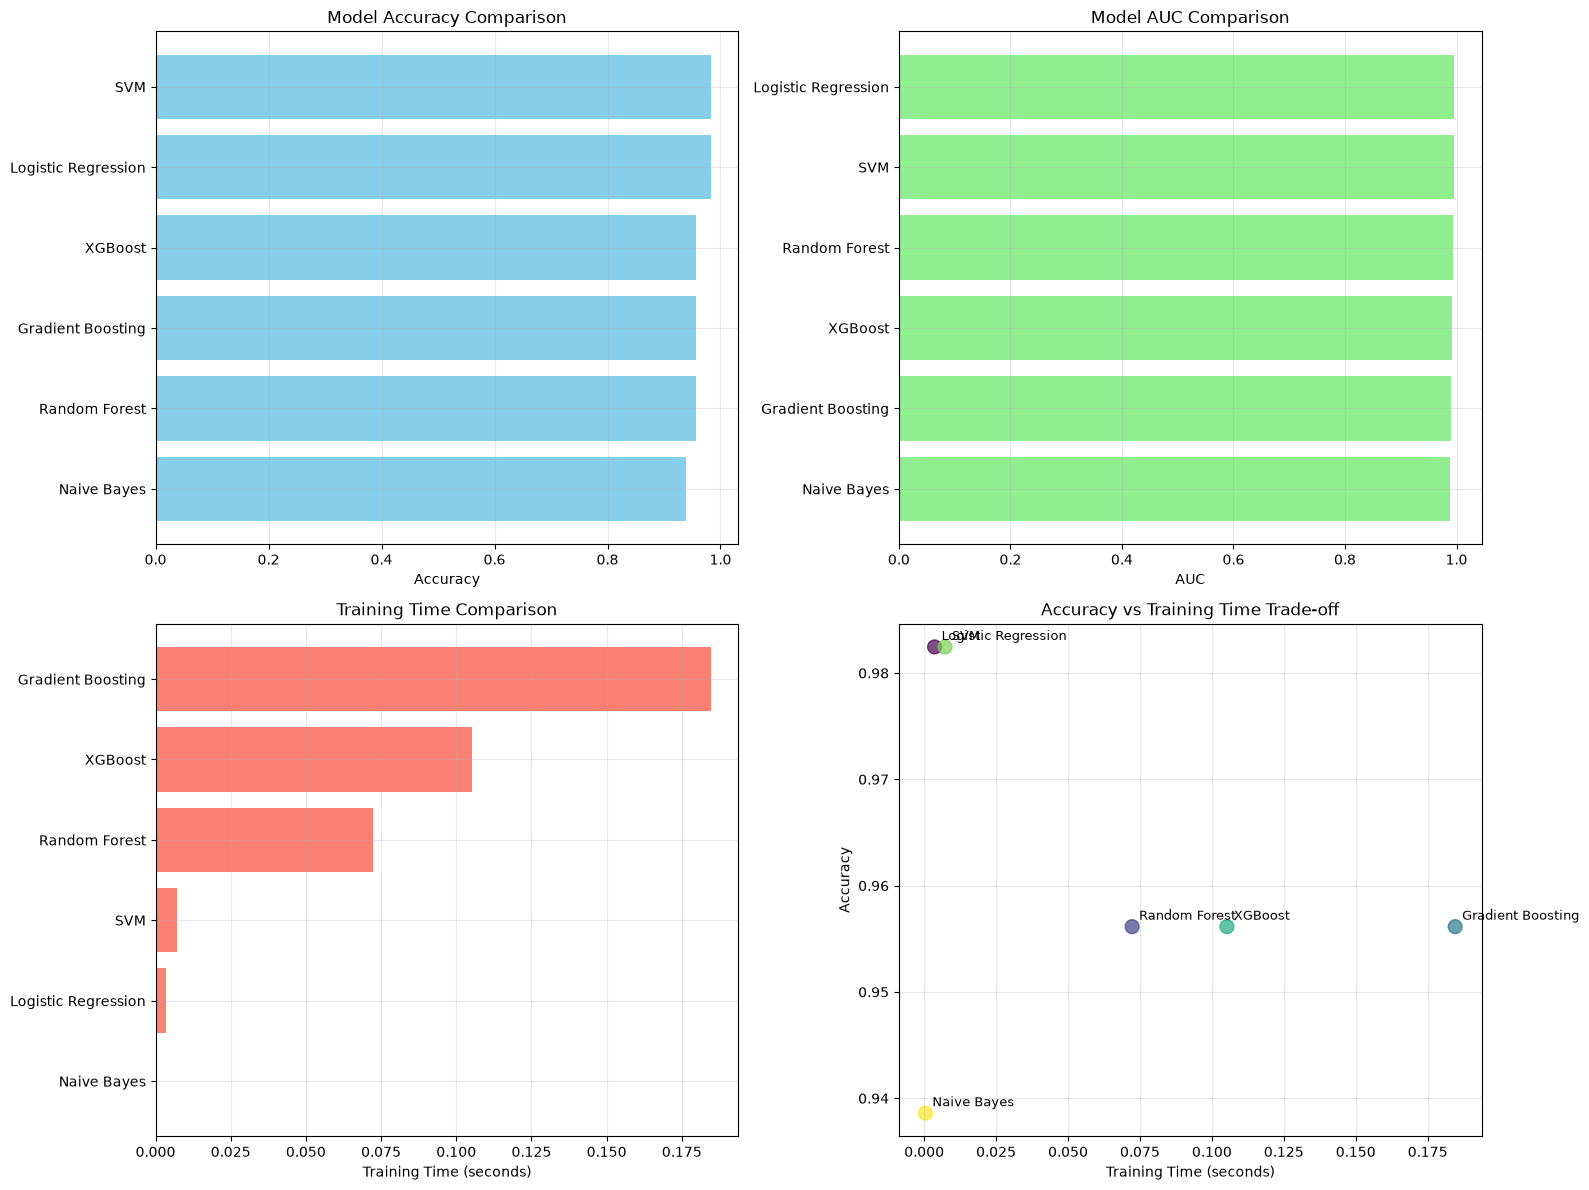

In [21]:
# Visualize comparison results
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# Accuracy comparison
results_df_sorted = results_df.sort_values('Accuracy', ascending=True)
axes[0,0].barh(results_df_sorted['Model'], results_df_sorted['Accuracy'], color='skyblue')
axes[0,0].set_xlabel('Accuracy')
axes[0,0].set_title('Model Accuracy Comparison')
axes[0,0].grid(True, alpha=0.3)

# AUC comparison (excluding models without AUC)
auc_results = results_df.dropna(subset=['AUC']).sort_values('AUC', ascending=True)
axes[0,1].barh(auc_results['Model'], auc_results['AUC'], color='lightgreen')
axes[0,1].set_xlabel('AUC')
axes[0,1].set_title('Model AUC Comparison')
axes[0,1].grid(True, alpha=0.3)

# Training time comparison
time_results = results_df.sort_values('Training Time (s)', ascending=True)
axes[1,0].barh(time_results['Model'], time_results['Training Time (s)'], color='salmon')
axes[1,0].set_xlabel('Training Time (seconds)')
axes[1,0].set_title('Training Time Comparison')
axes[1,0].grid(True, alpha=0.3)

# Accuracy vs Training Time scatter plot
axes[1,1].scatter(results_df['Training Time (s)'], results_df['Accuracy'], 
                  s=100, alpha=0.7, c=range(len(results_df)), cmap='viridis')
for i, model in enumerate(results_df['Model']):
    axes[1,1].annotate(model, 
                       (results_df.iloc[i]['Training Time (s)'], results_df.iloc[i]['Accuracy']),
                       xytext=(5, 5), textcoords='offset points', fontsize=9)
axes[1,1].set_xlabel('Training Time (seconds)')
axes[1,1].set_ylabel('Accuracy')
axes[1,1].set_title('Accuracy vs Training Time Trade-off')
axes[1,1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

### When to Use Each Algorithm:

**XGBoost:**
- ✅ Structured/tabular data
- ✅ High accuracy requirements
- ✅ Moderate to large datasets
- ✅ Mixed data types
- ❌ Need for high interpretability

**Random Forest:**
- ✅ Good baseline model
- ✅ Feature importance needed
- ✅ Robust to outliers
- ✅ Fast training
- ❌ Can overfit with many features

**Logistic Regression:**
- ✅ High interpretability needed
- ✅ Linear relationships
- ✅ Small datasets
- ✅ Fast training and prediction
- ❌ Complex non-linear patterns

**SVM:**
- ✅ High-dimensional data
- ✅ Clear margin of separation
- ✅ Small to medium datasets
- ❌ Large datasets (slow)

**Gradient Boosting (sklearn):**
- ✅ Similar to XGBoost but slower
- ✅ More conservative (less prone to overfitting)
- ❌ Not as optimized as XGBoost

---
## 8. Real-world Best Practices

Here are practical tips for using XGBoost effectively in real projects.

### 8.1 Handling Imbalanced Datasets

Clinical datasets are almost always imbalanced - the condition you care about is, thankfully,
the rare one. Screening cohorts, adverse-event registries and rare-disease panels routinely
run at 1-5% positives. XGBoost provides several ways to handle this.

The cohort below is generated with `make_classification` rather than taken from a real
registry, so the imbalance can be set exactly: think of it as a **screening cohort in which
1 patient in 10 has the condition**.


In [22]:
# Create an imbalanced screening cohort (simulated: 10% of patients have the condition)
X_imb, y_imb = make_classification(
    n_samples=1000, 
    n_features=20, 
    n_redundant=10,
    weights=[0.9, 0.1],  # 90% condition-negative, 10% condition-positive
    random_state=42
)

X_train_imb, X_test_imb, y_train_imb, y_test_imb = train_test_split(
    X_imb, y_imb, test_size=0.2, random_state=42, stratify=y_imb
)

print(f"Screening cohort class distribution: {np.bincount(y_train_imb)}")
print(f"Class imbalance ratio: {np.bincount(y_train_imb)[0] / np.bincount(y_train_imb)[1]:.1f}:1")

# Method 1: Using scale_pos_weight
scale_pos_weight = np.bincount(y_train_imb)[0] / np.bincount(y_train_imb)[1]

models_imbalanced = {
    'XGB Default': xgb.XGBClassifier(random_state=42),
    'XGB scale_pos_weight': xgb.XGBClassifier(scale_pos_weight=scale_pos_weight, random_state=42),
    'XGB class_weight balanced': xgb.XGBClassifier(random_state=42)  # We'll use sample_weight instead
}

from sklearn.utils.class_weight import compute_sample_weight

# Compare methods
imbalanced_results = []

for name, model in models_imbalanced.items():
    if name == 'XGB class_weight balanced':
        # Use sample weights for class balancing
        sample_weights = compute_sample_weight('balanced', y_train_imb)
        model.fit(X_train_imb, y_train_imb, sample_weight=sample_weights)
    else:
        model.fit(X_train_imb, y_train_imb)
    
    y_pred_imb = model.predict(X_test_imb)
    y_pred_proba_imb = model.predict_proba(X_test_imb)[:, 1]
    
    # Calculate various metrics for imbalanced data
    from sklearn.metrics import precision_score, recall_score, f1_score, precision_recall_curve
    
    accuracy = accuracy_score(y_test_imb, y_pred_imb)
    precision = precision_score(y_test_imb, y_pred_imb)
    recall = recall_score(y_test_imb, y_pred_imb)
    f1 = f1_score(y_test_imb, y_pred_imb)
    auc = roc_auc_score(y_test_imb, y_pred_proba_imb)
    
    imbalanced_results.append({
        'Method': name,
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1-Score': f1,
        'AUC': auc
    })

imbalanced_df = pd.DataFrame(imbalanced_results)
print("\nImbalanced Cohort Handling Comparison:")
print(imbalanced_df.round(4))

Screening cohort class distribution: [718  82]
Class imbalance ratio: 8.8:1



Imbalanced Cohort Handling Comparison:
                      Method  Accuracy  Precision  Recall  F1-Score     AUC
0                XGB Default      0.97     0.9375    0.75    0.8333  0.9461
1       XGB scale_pos_weight      0.97     0.9375    0.75    0.8333  0.9389
2  XGB class_weight balanced      0.97     0.9375    0.75    0.8333  0.9378


### 8.2 Hyperparameter Tuning Strategy

A systematic approach to tuning XGBoost hyperparameters.

In [23]:
# Hyperparameter tuning strategy: Start with coarse grid, then fine-tune

# Step 1: Coarse grid search on key parameters
param_grid_coarse = {
    'max_depth': [3, 6, 10],
    'learning_rate': [0.01, 0.1, 0.2],
    'n_estimators': [50, 100, 200],
    'subsample': [0.8, 1.0]
}

# Use a smaller subset for faster demonstration
xgb_tune = xgb.XGBClassifier(random_state=42)

# Coarse grid search
print("Step 1: Coarse Grid Search")
grid_search_coarse = GridSearchCV(
    xgb_tune, 
    param_grid_coarse, 
    cv=3,  # 3-fold CV for speed
    scoring='roc_auc',
    n_jobs=-1,
    verbose=0
)

# Fit on a smaller sample for demonstration
sample_size = 300
sample_indices = np.random.choice(len(X_train), sample_size, replace=True)
X_train_sample = X_train[sample_indices]
y_train_sample = y_train[sample_indices]

grid_search_coarse.fit(X_train_sample, y_train_sample)

print(f"Best coarse parameters: {grid_search_coarse.best_params_}")
print(f"Best coarse CV score: {grid_search_coarse.best_score_:.4f}")

Step 1: Coarse Grid Search


Best coarse parameters: {'learning_rate': 0.2, 'max_depth': 6, 'n_estimators': 50, 'subsample': 0.8}
Best coarse CV score: 0.9892


In [24]:
# Step 2: Fine-tune around best parameters
best_coarse = grid_search_coarse.best_params_

# Create fine-tuned grid around best parameters
param_grid_fine = {
    'max_depth': [best_coarse['max_depth'] - 1, best_coarse['max_depth'], best_coarse['max_depth'] + 1],
    'learning_rate': [best_coarse['learning_rate'] * 0.8, best_coarse['learning_rate'], best_coarse['learning_rate'] * 1.2],
    'n_estimators': [best_coarse['n_estimators'], best_coarse['n_estimators'] + 50],
    'subsample': [best_coarse['subsample']],  # Keep best value
    'reg_alpha': [0, 0.1, 0.5],  # Add regularization
}

# Remove negative or invalid values
param_grid_fine['max_depth'] = [max(1, x) for x in param_grid_fine['max_depth']]
param_grid_fine['learning_rate'] = [min(0.3, max(0.01, x)) for x in param_grid_fine['learning_rate']]

print("\nStep 2: Fine Grid Search")
grid_search_fine = GridSearchCV(
    xgb_tune, 
    param_grid_fine, 
    cv=3,
    scoring='roc_auc',
    n_jobs=-1,
    verbose=0
)

grid_search_fine.fit(X_train_sample, y_train_sample)

print(f"Best fine parameters: {grid_search_fine.best_params_}")
print(f"Best fine CV score: {grid_search_fine.best_score_:.4f}")
print(f"Improvement: {(grid_search_fine.best_score_ - grid_search_coarse.best_score_)*100:.2f} percentage points")

# Final model with best parameters
final_model = grid_search_fine.best_estimator_
final_model.fit(X_train, y_train)  # Train on full dataset

y_pred_final = final_model.predict(X_test)
final_accuracy = accuracy_score(y_test, y_pred_final)
print(f"\nFinal tuned model test accuracy: {final_accuracy:.4f}")


Step 2: Fine Grid Search


Best fine parameters: {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 50, 'reg_alpha': 0, 'subsample': 0.8}
Best fine CV score: 0.9892
Improvement: 0.00 percentage points



Final tuned model test accuracy: 0.9561


### 8.3 Model Persistence and Deployment

How to save, load, and deploy XGBoost models.

In [25]:
import pickle
import json
from pathlib import Path

# Create a models directory
models_dir = Path('../../data')
models_dir.mkdir(exist_ok=True)

# Method 1: XGBoost native format (recommended)
model_path = models_dir / 'xgb_breast_cancer_model.json'
final_model.save_model(str(model_path))

# Method 2: Pickle (includes all sklearn wrapper functionality)
pickle_path = models_dir / 'xgb_breast_cancer_model.pkl'
with open(pickle_path, 'wb') as f:
    pickle.dump(final_model, f)

print(f"Models saved to:")
print(f"  Native format: {model_path}")
print(f"  Pickle format: {pickle_path}")

# Save model metadata
metadata = {
    'model_type': 'XGBClassifier',
    'application': 'Breast mass diagnostic triage (teaching example - not for clinical use)',
    'features': feature_names,
    'n_features': len(feature_names),
    'classes': target_names.tolist(),
    'best_params': grid_search_fine.best_params_,
    'cv_score': grid_search_fine.best_score_,
    'test_accuracy': final_accuracy,
    'training_date': pd.Timestamp.now().isoformat()
}

metadata_path = models_dir / 'breast_cancer_model_metadata.json'
with open(metadata_path, 'w') as f:
    json.dump(metadata, f, indent=2)

print(f"  Metadata: {metadata_path}")


Models saved to:
  Native format: ../../data/xgb_breast_cancer_model.json
  Pickle format: ../../data/xgb_breast_cancer_model.pkl
  Metadata: ../../data/breast_cancer_model_metadata.json


In [26]:
# Load and test the saved model
print("Loading and testing saved models...\n")

# Method 1: Load XGBoost native format
loaded_model_native = xgb.XGBClassifier()
loaded_model_native.load_model(str(model_path))

# Method 2: Load pickle
with open(pickle_path, 'rb') as f:
    loaded_model_pickle = pickle.load(f)

# Load metadata
with open(metadata_path, 'r') as f:
    loaded_metadata = json.load(f)

print("Loaded metadata:")
for key, value in loaded_metadata.items():
    if key not in ['features']:  # Skip long feature list
        print(f"  {key}: {value}")

# Test predictions
test_sample = X_test[:5]
orig_pred = final_model.predict(test_sample)
native_pred = loaded_model_native.predict(test_sample)
pickle_pred = loaded_model_pickle.predict(test_sample)

print(f"\nPrediction consistency check (0=Malignant, 1=Benign):")
print(f"  Original model: {orig_pred}")
print(f"  Loaded native:  {native_pred}")
print(f"  Loaded pickle:  {pickle_pred}")
print(f"  All match: {np.array_equal(orig_pred, native_pred) and np.array_equal(orig_pred, pickle_pred)}")


Loading and testing saved models...

Loaded metadata:
  model_type: XGBClassifier
  application: Breast mass diagnostic triage (teaching example - not for clinical use)
  n_features: 30
  classes: ['Malignant', 'Benign']
  best_params: {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 50, 'reg_alpha': 0, 'subsample': 0.8}
  cv_score: 0.9892190162778398
  test_accuracy: 0.956140350877193
  training_date: 2026-10-03T10:27:08.637255

Prediction consistency check (0=Malignant, 1=Benign):
  Original model: [0 1 0 0 0]
  Loaded native:  [0 1 0 0 0]
  Loaded pickle:  [0 1 0 0 0]
  All match: True


### 8.4 Common Pitfalls and How to Avoid Them

Here are some common mistakes when using XGBoost and how to avoid them:

In [27]:
# Pitfall 1: Not using proper validation
print("❌ PITFALL 1: Using the same data for training and validation")
print("\n❌ Bad practice:")
bad_model = xgb.XGBClassifier(n_estimators=1000, random_state=42)
bad_model.fit(X_train, y_train)
train_accuracy = accuracy_score(y_train, bad_model.predict(X_train))
test_accuracy = accuracy_score(y_test, bad_model.predict(X_test))
print(f"Training accuracy: {train_accuracy:.4f}")
print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Overfitting gap: {train_accuracy - test_accuracy:.4f}")

print("\n✅ Good practice: Use validation set and early stopping")
X_train_val, X_val_val, y_train_val, y_val_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

good_model = xgb.XGBClassifier(
    n_estimators=1000,
    learning_rate=0.05,
    random_state=42,
    callbacks=[xgb.callback.EarlyStopping(rounds=10, save_best=True)]
)

good_model.fit(
    X_train_val, y_train_val,
    eval_set=[(X_val_val, y_val_val)],
    verbose=False
)

train_accuracy_good = accuracy_score(y_train_val, good_model.predict(X_train_val))
test_accuracy_good = accuracy_score(y_test, good_model.predict(X_test))
print(f"Training accuracy: {train_accuracy_good:.4f}")
print(f"Test accuracy: {test_accuracy_good:.4f}")
print(f"Overfitting gap: {train_accuracy_good - test_accuracy_good:.4f}")
print(f"Stopped at iteration: {good_model.best_iteration}")

❌ PITFALL 1: Using the same data for training and validation



❌ Bad practice:


Training accuracy: 1.0000
Test accuracy: 0.9561
Overfitting gap: 0.0439

✅ Good practice: Use validation set and early stopping


Training accuracy: 1.0000
Test accuracy: 0.9474
Overfitting gap: 0.0526
Stopped at iteration: 163


In [28]:
# Pitfall 2: Not preprocessing categorical features properly
print("\n❌ PITFALL 2: Not handling categorical features properly")

# Create a dataset with categorical features
categorical_data = pd.DataFrame({
    'numeric_feature': np.random.randn(1000),
    'categorical_feature': np.random.choice(['A', 'B', 'C', 'D'], 1000),
    'target': np.random.choice([0, 1], 1000)
})

print("❌ Bad practice: Using strings directly")
try:
    bad_cat_model = xgb.XGBClassifier()
    bad_cat_model.fit(categorical_data[['numeric_feature', 'categorical_feature']], 
                      categorical_data['target'])
except Exception as e:
    print(f"Error: {str(e)}")

print("\n✅ Good practice: Proper encoding")
# Method 1: Label Encoding for ordinal features
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
categorical_data['categorical_encoded'] = le.fit_transform(categorical_data['categorical_feature'])

good_cat_model = xgb.XGBClassifier(enable_categorical=True)  # XGBoost 1.6+
good_cat_model.fit(categorical_data[['numeric_feature', 'categorical_encoded']], 
                   categorical_data['target'])

print("Successfully trained with encoded categorical features")
print(f"Unique values in categorical feature: {categorical_data['categorical_feature'].nunique()}")
print(f"Encoded values range: {categorical_data['categorical_encoded'].min()} to {categorical_data['categorical_encoded'].max()}")


❌ PITFALL 2: Not handling categorical features properly
❌ Bad practice: Using strings directly
Error: DataFrame.dtypes for data must be int, float, bool or category. When categorical type is supplied, the experimental DMatrix parameter`enable_categorical` must be set to `True`.  Invalid columns:categorical_feature: str

✅ Good practice: Proper encoding


Successfully trained with encoded categorical features
Unique values in categorical feature: 4
Encoded values range: 0 to 3


In [29]:
# Pitfall 3: Not considering feature scaling (though XGBoost is relatively robust)
print("\n❌ PITFALL 3: Extreme feature scales can still affect XGBoost")

# Create features with very different scales
X_scaled_demo = np.column_stack([
    X_train[:, 0] * 1e6,  # Very large scale
    X_train[:, 1] * 1e-6,  # Very small scale
    X_train[:, 2:5]        # Normal scale
])

X_test_scaled_demo = np.column_stack([
    X_test[:, 0] * 1e6,
    X_test[:, 1] * 1e-6,
    X_test[:, 2:5]
])

# Without scaling
model_unscaled = xgb.XGBClassifier(random_state=42)
model_unscaled.fit(X_scaled_demo, y_train)
acc_unscaled = accuracy_score(y_test, model_unscaled.predict(X_test_scaled_demo))

# With scaling
scaler = StandardScaler()
X_scaled_demo_normalized = scaler.fit_transform(X_scaled_demo)
X_test_scaled_demo_normalized = scaler.transform(X_test_scaled_demo)

model_scaled = xgb.XGBClassifier(random_state=42)
model_scaled.fit(X_scaled_demo_normalized, y_train)
acc_scaled = accuracy_score(y_test, model_scaled.predict(X_test_scaled_demo_normalized))

print(f"Accuracy without scaling: {acc_unscaled:.4f}")
print(f"Accuracy with scaling: {acc_scaled:.4f}")
print(f"Difference: {acc_scaled - acc_unscaled:.4f}")
print("\nNote: XGBoost is generally robust to feature scaling, but extreme scales can still impact performance.")


❌ PITFALL 3: Extreme feature scales can still affect XGBoost


Accuracy without scaling: 0.8947
Accuracy with scaling: 0.8947
Difference: 0.0000

Note: XGBoost is generally robust to feature scaling, but extreme scales can still impact performance.


---
## Summary and Key Takeaways

### Key Points:

1. **XGBoost Excellence**: XGBoost is particularly effective for structured/tabular data like the nuclear measurements used here, and often achieves state-of-the-art results

2. **Parameter Understanding**: Key parameters include:
   - `learning_rate`: Controls step size (0.01-0.3)
   - `max_depth`: Tree depth (3-10)
   - `n_estimators`: Number of trees (100-1000+)
   - `subsample`, `colsample_bytree`: Prevent overfitting
   - `reg_alpha`, `reg_lambda`: Regularization

3. **Advanced Features**:
   - Built-in missing value handling
   - Early stopping for optimal training
   - Cross-validation with native XGBoost functions
   - Custom evaluation metrics

4. **Model Interpretation**: SHAP provides excellent model explanations - critical in clinical settings, where a clinician has to be able to see WHY a case was ranked as concerning before acting on it

5. **Best Practices**:
   - Always use proper validation
   - Handle categorical features appropriately
   - Use early stopping to prevent overfitting
   - Consider class imbalance with `scale_pos_weight`
   - Systematic hyperparameter tuning

### Clinical Applications:
- **Diagnostic triage**: ranking which cases a pathologist should review first, the use case demonstrated here
- **Risk stratification**: understanding which measurements are most diagnostic
- **Clinician trust**: SHAP explanations make the model's reasoning inspectable
- **Quality control**: the measurements a model leans on are the ones worth measuring carefully

### A necessary caveat

This notebook is a **teaching example**. A model that is genuinely used in care needs a great
deal more than a good test-set AUC: prospective validation on the population it will actually
be used in, evaluation of subgroup performance and bias, a defined role in the clinical
workflow with a human decision-maker, monitoring for drift after deployment, and - for a
diagnostic claim - regulatory clearance (in Canada, a Health Canada medical device licence for software as a
medical device; elsewhere FDA, UKCA/MHRA or EU MDR).
Retrospective accuracy on a public dataset is the beginning of that process, not the end of it.

### Next Steps:
- Practice with different datasets
- Experiment with hyperparameter combinations
- Try XGBoost in Kaggle competitions
- Explore LightGBM and CatBoost for comparison
- Learn about ensemble methods combining multiple models

### Additional Resources:
- [XGBoost Documentation](https://xgboost.readthedocs.io/)
- [SHAP Documentation](https://shap.readthedocs.io/)
- [Breast Cancer Wisconsin (Diagnostic) dataset](https://scikit-learn.org/stable/datasets/toy_dataset.html#breast-cancer-dataset)
- [Kaggle Learn: Intermediate Machine Learning](https://www.kaggle.com/learn/intermediate-machine-learning)


In [30]:
# Final summary of our diagnostic triage model
print("WORKSHOP COMPLETE!")
print("\nFinal Model Summary:")
print(f"  Algorithm: XGBoost Classifier")
print(f"  Best Parameters: {grid_search_fine.best_params_}")
print(f"  Cross-Validation Score: {grid_search_fine.best_score_:.4f}")
print(f"  Test Accuracy: {final_accuracy:.4f}")
print(f"  Dataset: Breast Cancer Wisconsin (Malignant vs Benign)")
print(f"  Features: {len(feature_names)} nuclear measurements")
print(f"  Training Samples: {len(X_train)}")
print(f"  Test Samples: {len(X_test)}")

print("\nTools Covered:")
print("  - XGBoost fundamentals and implementation")
print("  - Parameter tuning and optimization")
print("  - Advanced features (early stopping, CV, missing values)")
print("  - Model interpretation with SHAP")
print("  - Comparison with other algorithms")
print("  - Real-world best practices")
print("  - Model persistence and deployment prep")

print("\nClinical Application Value:")
print("  - Learned to separate malignant from benign masses using nuclear measurements")
print("  - Understood which measurements are most diagnostic")
print("  - Can explain model decisions, which is what earns clinician trust")
print("  - Ready to apply XGBoost to other clinical prediction problems")

print("\nReminder: this is a teaching example. A deployed diagnostic model needs")
print("prospective validation, bias evaluation and regulatory clearance.")

print("\nYou're now ready to use XGBoost effectively in your projects!")


WORKSHOP COMPLETE!

Final Model Summary:
  Algorithm: XGBoost Classifier
  Best Parameters: {'learning_rate': 0.2, 'max_depth': 5, 'n_estimators': 50, 'reg_alpha': 0, 'subsample': 0.8}
  Cross-Validation Score: 0.9892
  Test Accuracy: 0.9561
  Dataset: Breast Cancer Wisconsin (Malignant vs Benign)
  Features: 30 nuclear measurements
  Training Samples: 455
  Test Samples: 114

Tools Covered:
  - XGBoost fundamentals and implementation
  - Parameter tuning and optimization
  - Advanced features (early stopping, CV, missing values)
  - Model interpretation with SHAP
  - Comparison with other algorithms
  - Real-world best practices
  - Model persistence and deployment prep

Clinical Application Value:
  - Learned to separate malignant from benign masses using nuclear measurements
  - Understood which measurements are most diagnostic
  - Can explain model decisions, which is what earns clinician trust
  - Ready to apply XGBoost to other clinical prediction problems

Reminder: this is a te